<a href="https://colab.research.google.com/github/vigneshkv200/Strategic-Customer-Subscription-Prediction/blob/main/Portuguese_Bank_marketing_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Portuguese Bank Marketing — Customer Subscription Prediction

### Project Overview

This project focuses on predicting whether a bank customer will subscribe to a **term deposit** based on customer demographics, financial information, previous campaign interactions, and socio-economic indicators.

The dataset contains information collected from direct phone marketing campaigns conducted by a Portuguese banking institution between **May 2008 and November 2010**.

###  Business Objective

The primary objective is to build a machine learning model that can help the bank's marketing team:

- Identify customers who are more likely to subscribe to a term deposit.
- Improve the efficiency of marketing campaigns.
- Reduce unnecessary calls to customers who are unlikely to subscribe.
- Support data-driven customer targeting decisions.

###  Machine Learning Objective

This is a **binary classification problem**.

| Target| Meaning|
|---|---|
| `yes` | Customer subscribed to a term deposit |
|  `no` | Customer did not subscribe|

We will develop and compare multiple classification algorithms:

1. Logistic Regression
2. Random Forest
3. XGBoost
4. CatBoost
5. LightGBM

The best-performing model will then be **optimized and evaluated using an appropriate probability threshold** before making the final production recommendation.

###  Important Data Consideration

The `duration` variable represents the duration of the last call. Although it is highly predictive of the target, it is **not known before a call takes place**.

Therefore, for a realistic customer-targeting model, `duration` will be excluded to avoid data leakage and unrealistic predictions.

###  Project Workflow

**Data Understanding → Exploratory Data Analysis → Preprocessing → Model Training → Model Comparison → Hyperparameter Optimization → Threshold Optimization → Final Evaluation → Business Recommendations**

#### BOX 2 — Importing Libraries

Before starting the analysis, I am importing the basic libraries required for this project.

I will mainly use:
- Pandas and NumPy for working with the data
- Matplotlib and Seaborn for visualization
- Warnings to keep the notebook output clean

The machine learning libraries will be imported later when we start the preprocessing and modelling sections.

In [ ]:
!pip install mlflow
!pip install catboost
!pip install lightgbm
!pip install xgboost
!pip install shap

In [ ]:
# Basic libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# For reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", None)

# Plot style
sns.set_style("whitegrid")

from sklearn.ensemble import RandomForestClassifier


print("Libraries imported successfully.")

Libraries imported successfully.


### BOX 3 — Loading the Dataset

Now I will load the `bank-additional-full.csv` dataset provided for the project.

The dataset contains customer information, previous campaign details and economic indicators, with `y` as the target variable.

In [ ]:
# Load the dataset
df = pd.read_csv("/content/bank-additional-full.csv", sep=";")

print("Dataset loaded successfully.")
print("Shape of the dataset:", df.shape)

df.head()

Dataset loaded successfully.
Shape of the dataset: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### BOX 4 — Understanding the Dataset

Before doing any preprocessing, I want to understand what kind of data I am working with.

I will first check:
- Number of rows and columns
- Column names
- Data types
- Missing values
- Basic statistics

This will help decide what preprocessing is actually required instead of applying transformations blindly.

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 41188
Number of columns: 21

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Check actual missing values
print("Missing values:")
print(df.isnull().sum())

# Check 'unknown' values in categorical columns
print("\n'Unknown' values:")
unknown_counts = (df == "unknown").sum()
print(unknown_counts[unknown_counts > 0])

Missing values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

'Unknown' values:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64


At this stage I'm not changing anything in the dataset. I'm first trying to understand its structure, the data types and whether there are missing or unknown values. Based on this analysis, I'll decide what preprocessing is actually necessary

### BOX 5 — Target Variable Analysis

Before building any model, I want to understand the distribution of our target variable.

The target variable `y` tells us whether a customer subscribed to the term deposit.

First, I will look at the number of customers in each class and then visualize the distribution.

In [ ]:
# Check the target distribution
target_counts = df["y"].value_counts()

print("Target variable distribution:")
print(target_counts)

print("\nPercentage distribution:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

Target variable distribution:
y
no     36548
yes     4640
Name: count, dtype: int64

Percentage distribution:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


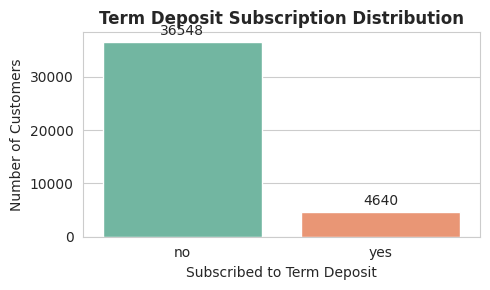

In [ ]:
plt.figure(figsize=(5, 3))

ax = sns.countplot(
    data=df,
    x="y",
    hue="y",
    palette="Set2",
    legend=False
)

plt.title("Term Deposit Subscription Distribution", fontsize=12, fontweight="bold")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Customers")

# Add values on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

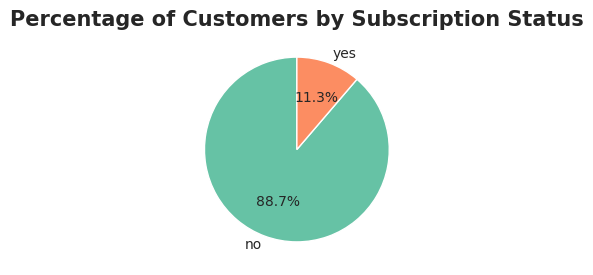

In [ ]:
target_percentage = df["y"].value_counts(normalize=True) * 100

plt.figure(figsize=(3, 3))

plt.pie(
    target_percentage,
    labels=target_percentage.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", 2)
)

plt.title("Percentage of Customers by Subscription Status",
          fontsize=15, fontweight="bold")

plt.show()

#### Key Insight

The target variable is not evenly distributed. Most customers did not subscribe to the term deposit, while a much smaller proportion subscribed.

This indicates that the dataset has **class imbalance**.

Therefore, during model evaluation, I should not depend only on accuracy. Metrics such as **precision, recall, F1-score and ROC-AUC** will also be considered when comparing the models.

### BOX 6 — Numerical Variable Analysis

The dataset contains several numerical variables related to the customer, campaign activity and the economic environment.

I will first look at their distributions to understand:
- The typical range of values
- Possible outliers
- Skewed variables
- Whether any variables need special treatment during preprocessing

In [ ]:
# Identify numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(list(numeric_cols))

Numerical columns:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [ ]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


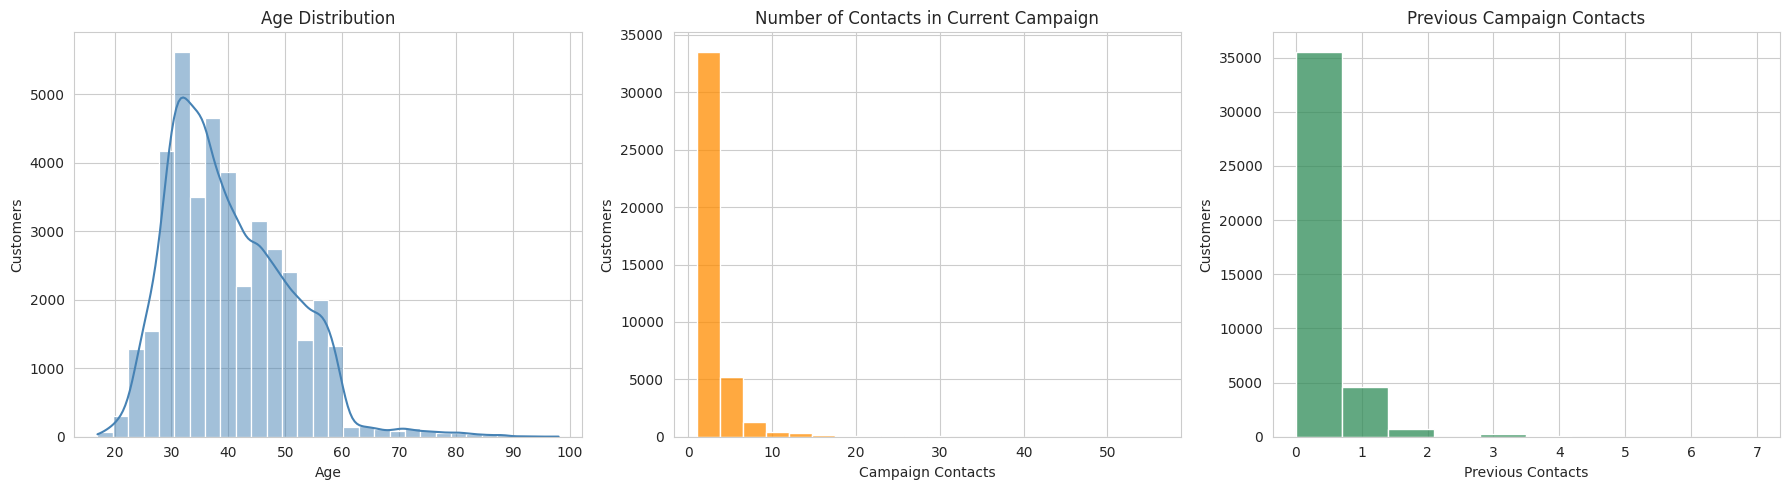

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["age"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Customers")

sns.histplot(df["campaign"], bins=20, kde=False, ax=axes[1], color="darkorange")
axes[1].set_title("Number of Contacts in Current Campaign")
axes[1].set_xlabel("Campaign Contacts")
axes[1].set_ylabel("Customers")

sns.histplot(df["previous"], bins=10, kde=False, ax=axes[2], color="seagreen")
axes[2].set_title("Previous Campaign Contacts")
axes[2].set_xlabel("Previous Contacts")
axes[2].set_ylabel("Customers")

plt.tight_layout()
plt.show()

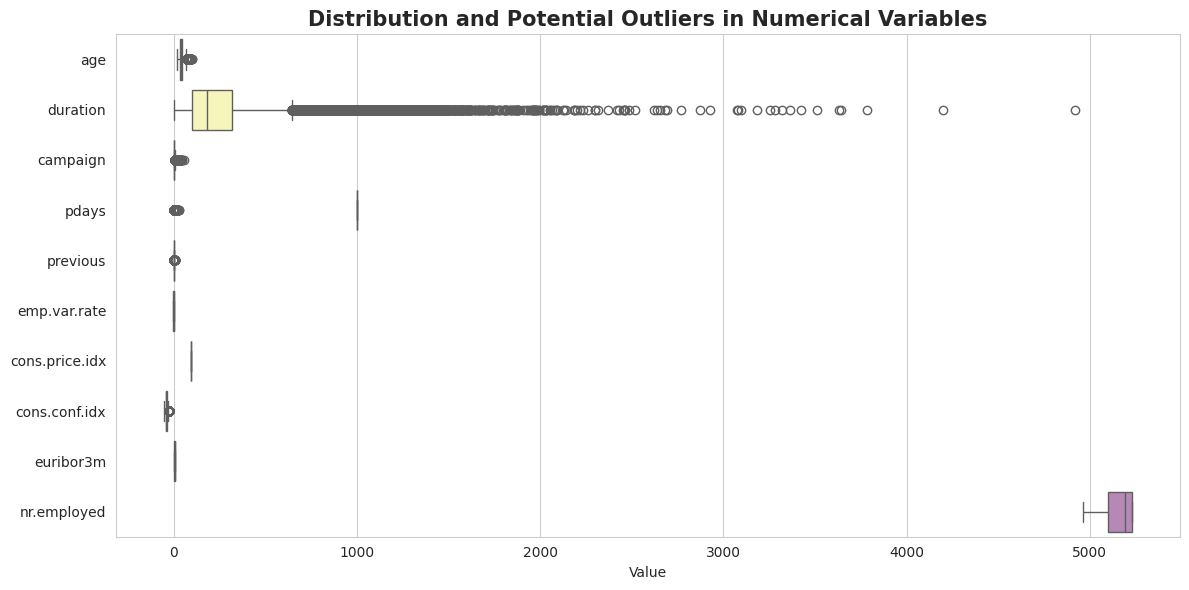

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[numeric_cols],
    orient="h",
    palette="Set3"
)

plt.title("Distribution and Potential Outliers in Numerical Variables",
          fontsize=15, fontweight="bold")
plt.xlabel("Value")

plt.tight_layout()
plt.show()

#### Key Insight

The numerical variables have very different ranges and distributions.

For example, `age` represents customer demographics, while variables such as `campaign`, `previous` and `pdays` represent campaign history.

Some variables also contain extreme values or highly skewed distributions. These observations will be considered during preprocessing rather than removing values blindly.

Here I'm trying to understand the numerical variables before preprocessing. I can see that they have different ranges and some are skewed. I won't simply remove every outlier because some extreme values can represent genuine customer behaviour. I'll decide how to handle them based on the variable and the model.

### BOX 7 — Categorical Variable Analysis

The dataset contains several categorical variables that describe customer characteristics and campaign information.

I will analyse the major categorical variables to understand how customers are distributed across different groups.

I will also compare these groups with the target variable `y` to see whether some customer segments show different subscription behaviour.

In [ ]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(list(categorical_cols))

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


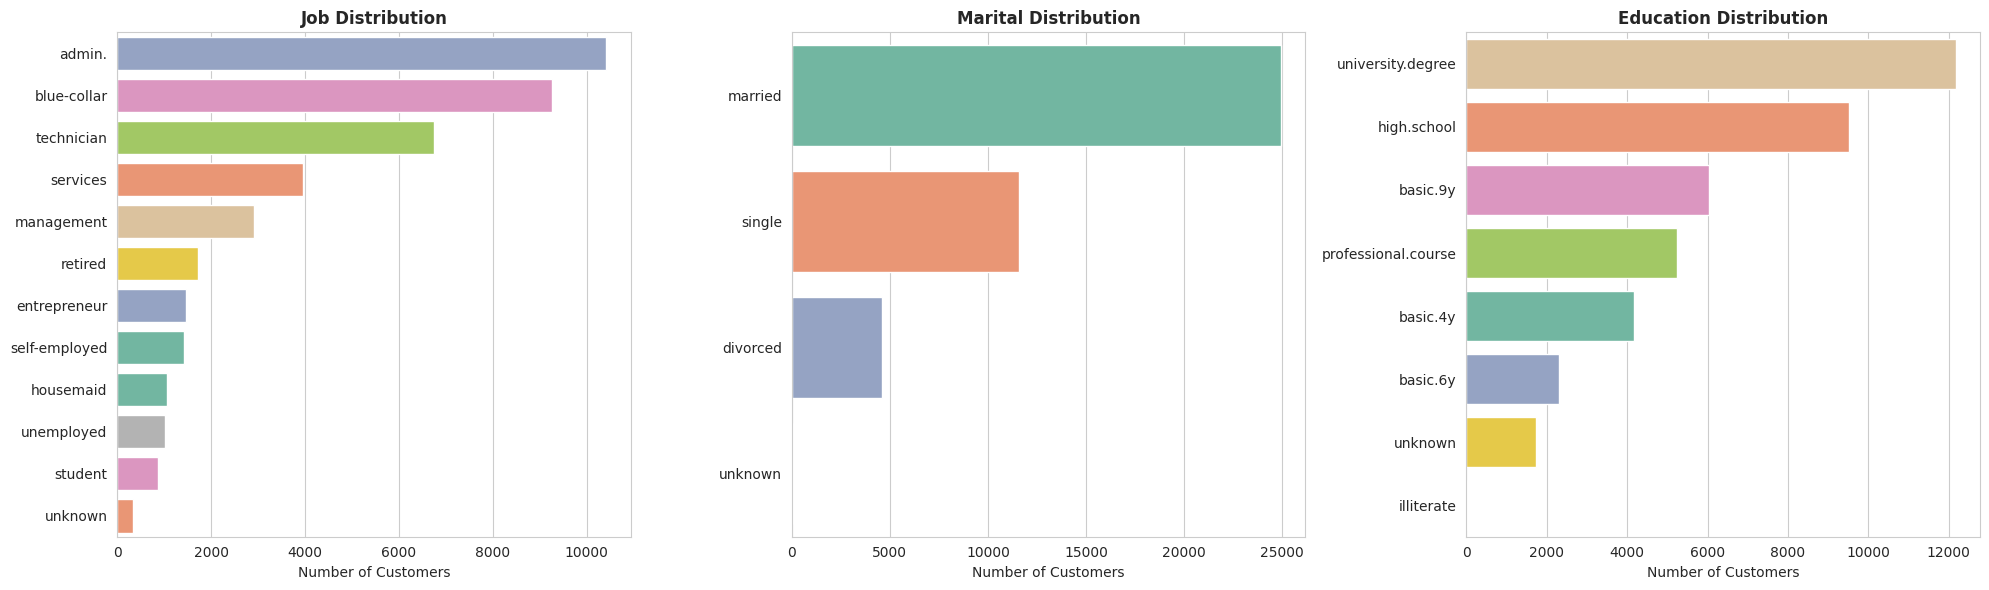

In [ ]:
# Customer-related categorical variables
customer_cats = ["job", "marital", "education"]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, col in zip(axes, customer_cats):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        y=col,
        order=order,
        hue=col,
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col.title()} Distribution", fontweight="bold")
    ax.set_xlabel("Number of Customers")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

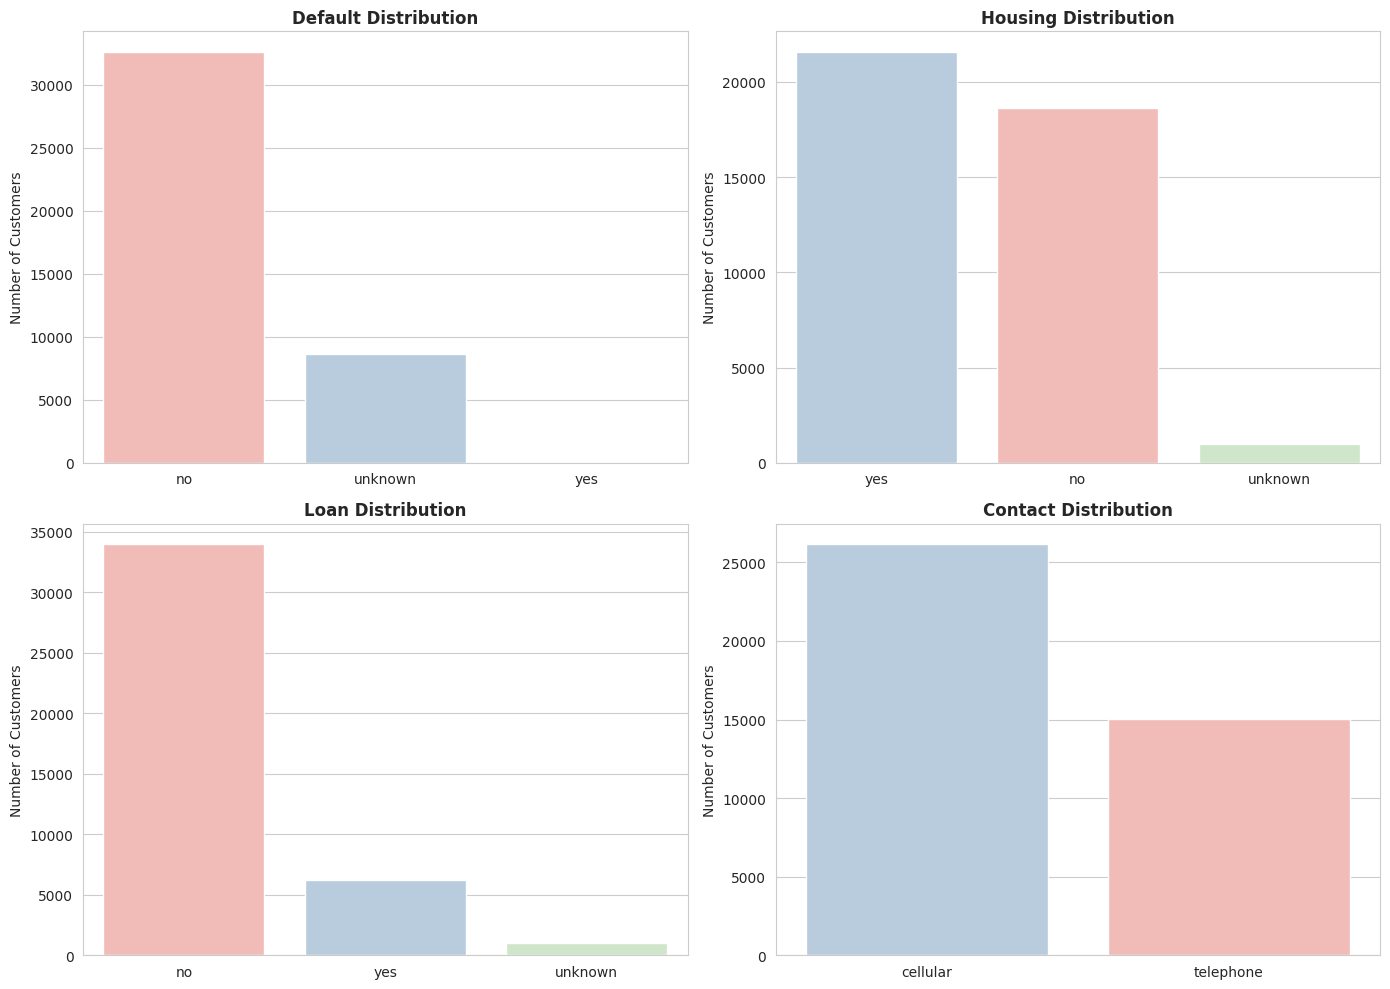

In [ ]:
financial_cats = ["default", "housing", "loan", "contact"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, financial_cats):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        hue=col,
        palette="Pastel1",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col.title()} Distribution", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

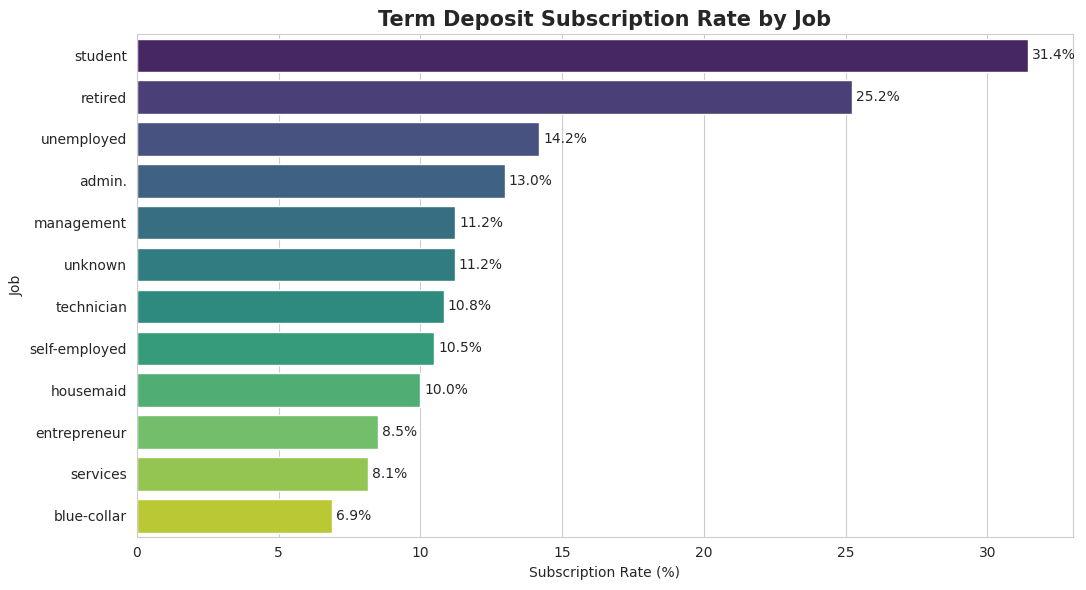

In [ ]:
job_subscription = (
    df.groupby("job")["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=job_subscription.values,
    y=job_subscription.index,
    hue=job_subscription.index,
    palette="viridis",
    legend=False
)

plt.title("Term Deposit Subscription Rate by Job",
          fontsize=15, fontweight="bold")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

#### Key Insight

The categorical variables show noticeable differences in customer composition.

More importantly, the subscription rate is not the same across all job categories. This suggests that customer characteristics may contain useful information for predicting term-deposit subscription.

However, differences in subscription rate alone are not enough to decide which variables are important. The machine learning models will evaluate the variables together.

Here I'm looking at the categorical variables from two perspectives. First, I want to understand how the customers are distributed. Then I'm checking whether subscription behaviour changes across different customer segments. For example, the subscription rate varies across job categories, which suggests these features could be useful for prediction.

### BOX 8 — Campaign & Contact Analysis

The dataset also contains information about how customers were contacted during the marketing campaigns.

Here I will analyse:
- Contact method
- Month of last contact
- Day of the week
- Previous campaign outcome
- Number of contacts made during the current campaign
- Previous campaign contacts

The aim is to identify patterns in campaign behaviour and customer response.

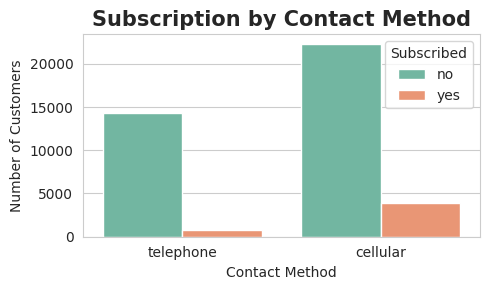

In [ ]:
plt.figure(figsize=(5, 3))

sns.countplot(
    data=df,
    x="contact",
    hue="y",
    palette="Set2"
)

plt.title("Subscription by Contact Method", fontsize=15, fontweight="bold")
plt.xlabel("Contact Method")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

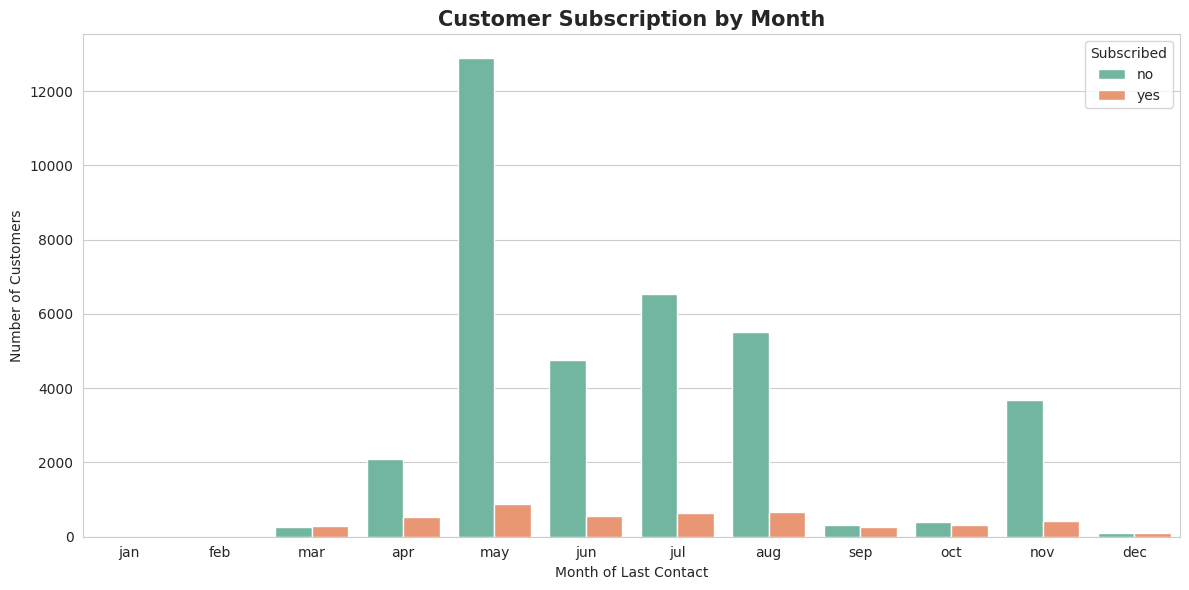

In [ ]:
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="month",
    order=month_order,
    hue="y",
    palette="Set2"
)

plt.title("Customer Subscription by Month",
          fontsize=15, fontweight="bold")
plt.xlabel("Month of Last Contact")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

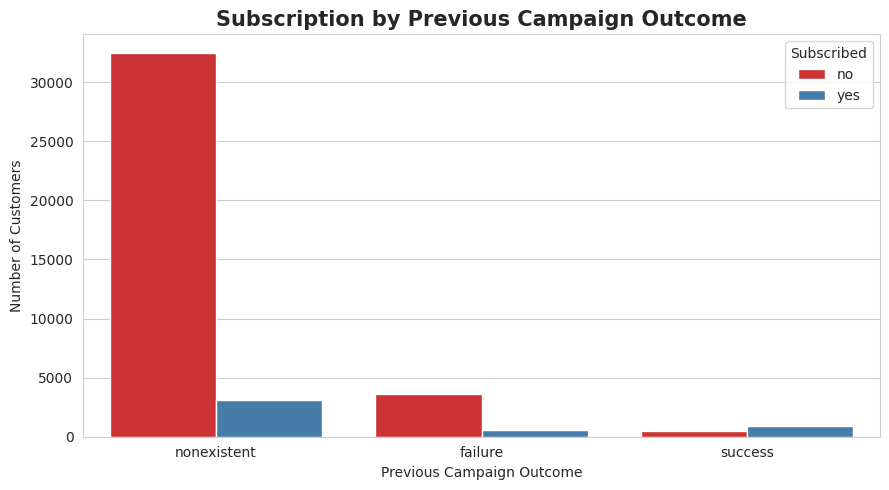

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="poutcome",
    hue="y",
    palette="Set1"
)

plt.title("Subscription by Previous Campaign Outcome",
          fontsize=15, fontweight="bold")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

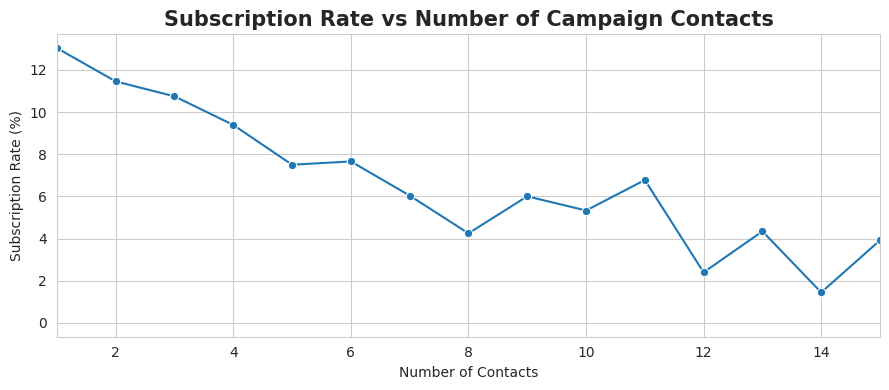

In [ ]:
campaign_rate = (
    df.groupby("campaign")["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
)

plt.figure(figsize=(9, 4))

sns.lineplot(
    x=campaign_rate.index,
    y=campaign_rate.values,
    marker="o"
)

plt.title("Subscription Rate vs Number of Campaign Contacts",
          fontsize=15, fontweight="bold")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")
plt.xlim(1, 15)

plt.tight_layout()
plt.show()

#### Key Insight

The campaign-related variables show that customer response is not uniform across different contact conditions.

In particular, the previous campaign outcome shows a noticeable difference in subscription behaviour. Customers with a successful previous campaign outcome appear to have a higher subscription rate than customers with other previous outcomes.

The number of contacts during the current campaign also shows a changing relationship with subscription rate.

These patterns suggest that previous campaign history and contact strategy may provide useful information for the prediction model.

Now I'm looking at the campaign side of the data. One interesting pattern is the previous campaign outcome. Customers who had a successful previous campaign outcome show a much higher subscription rate. This tells us that previous interaction history may be useful when predicting future customer behaviour

### BOX 9 — Correlation & Relationship Analysis

After looking at the individual variables, I will now check the relationships between the numerical features.

A correlation matrix is useful here because some of the economic indicators and campaign-related variables may be related to each other.

This is only an exploratory step. I will not remove features based on correlation alone.

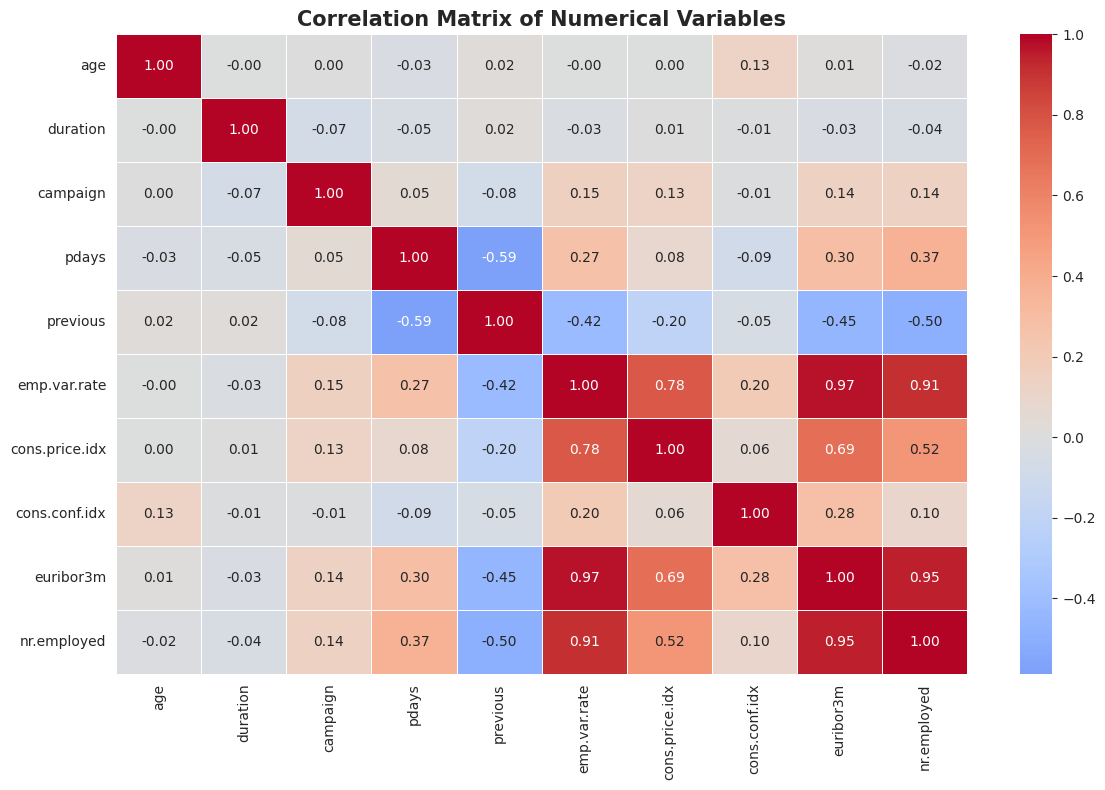

In [ ]:
# Correlation between numerical variables
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Correlation Matrix of Numerical Variables",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# Get the upper triangle of the correlation matrix
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

strong_correlations = (
    upper.stack()
         .reset_index()
)

strong_correlations.columns = ["Feature 1", "Feature 2", "Correlation"]

strong_correlations["Absolute Correlation"] = (
    strong_correlations["Correlation"].abs()
)

strong_correlations.sort_values(
    "Absolute Correlation",
    ascending=False
).head(10)

,Feature 1,Feature 2,Correlation,Absolute Correlation
37,emp.var.rate,euribor3m,0.972245,0.972245
44,euribor3m,nr.employed,0.945154,0.945154
38,emp.var.rate,nr.employed,0.906970,0.906970
35,emp.var.rate,cons.price.idx,0.775334,0.775334
40,cons.price.idx,euribor3m,0.688230,0.688230
24,pdays,previous,-0.587514,0.587514
41,cons.price.idx,nr.employed,0.522034,0.522034
34,previous,nr.employed,-0.501333,0.501333
33,previous,euribor3m,-0.454494,0.454494
30,previous,emp.var.rate,-0.420489,0.420489


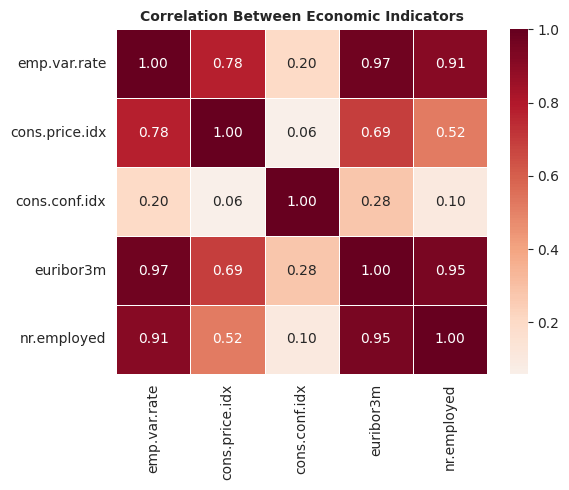

In [ ]:
economic_cols = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

plt.figure(figsize=(6, 5))

sns.heatmap(
    df[economic_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5
)

plt.title(
    "Correlation Between Economic Indicators",
    fontsize=10,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Key Insight

The correlation analysis shows that some numerical variables have relatively strong relationships with each other, particularly among the economic indicators.

This is important because highly related variables may contain overlapping information.

However, correlation does not automatically mean that a feature should be removed. Since we are going to compare several different machine learning algorithms, the final feature selection will be based on model performance and the nature of each variable.

The heatmap helps me understand how the numerical variables are related to each other. I can see that some of the economic indicators are strongly correlated. But I won't remove them just because of correlation, because correlation between input features doesn't automatically mean that they're useless. I'll let the modelling stage and validation results guide that decision.

### BOX 10 — Data Quality Check & Preprocessing Decisions

Before building the models, I will perform a final data-quality check and decide how each issue should be handled.

The main things I need to check are:

- Duplicate records
- Missing values
- `unknown` values
- The special `999` value in `pdays`
- The `duration` feature
- Target encoding

I will make these decisions based on the meaning of each variable rather than applying the same treatment to every column.

In [ ]:
# Check for duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 12


In [ ]:
# Check missing values
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

if len(missing_values) == 0:
    print("No actual NaN/null values found in the dataset.")
else:
    print(missing_values)

No actual NaN/null values found in the dataset.


In [ ]:
# Count 'unknown' values in each column
unknown_counts = (df == "unknown").sum()

unknown_counts = unknown_counts[unknown_counts > 0].sort_values(
    ascending=False
)

print("Columns containing 'unknown' values:")
display(unknown_counts)

Columns containing 'unknown' values:


,0
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


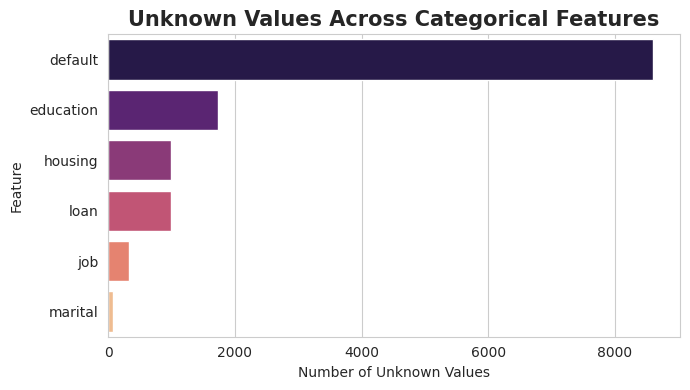

In [ ]:
plt.figure(figsize=(7, 4))

sns.barplot(
    x=unknown_counts.values,
    y=unknown_counts.index,
    hue=unknown_counts.index,
    palette="magma",
    legend=False
)

plt.title(
    "Unknown Values Across Categorical Features",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Number of Unknown Values")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
pdays_999 = (df["pdays"] == 999).sum()
pdays_999_percentage = (pdays_999 / len(df)) * 100

print("Customers with pdays = 999:", pdays_999)
print(f"Percentage of dataset: {pdays_999_percentage:.2f}%")

Customers with pdays = 999: 39673
Percentage of dataset: 96.32%


In [ ]:
print("Duration statistics:")
display(df["duration"].describe())

print("\nNumber of zero-duration calls:",
      (df["duration"] == 0).sum())

Duration statistics:


,duration
count,41188.000000
mean,258.285010
std,259.279249
min,0.000000
25%,102.000000
50%,180.000000
75%,319.000000
max,4918.000000



Number of zero-duration calls: 4


#### Preprocessing Decisions

Based on the data-quality checks and the meaning of the variables, the following decisions will be used:

| Issue | Decision | Reason |
|---|---|---|
| Duplicate rows | Remove if present | Avoid giving repeated observations additional influence |
| NaN values | Check and handle if present | Maintain a clean dataset |
| `unknown` values | Treat as a valid category initially | `unknown` represents unavailable information rather than automatically being an error |
| `pdays = 999` | Keep / transform carefully | 999 indicates that the customer was not previously contacted |
| `duration` | Remove from production model | It is only known after the call and can cause data leakage |
| Target `y` | Encode `yes = 1`, `no = 0` | Required for binary classification |

The final preprocessing will be performed after this analysis so that the transformations are applied consistently to the training and test data.

This is where I convert the EDA findings into preprocessing decisions. For example, I won't simply replace all unknown values with the mode because unknown itself can carry information. For pdays, 999 has a specific meaning in this dataset, so I need to handle it based on that meaning. Most importantly, I'm removing duration because it wouldn't be available when the bank is deciding whom to call.

### BOX 11 — Data Cleaning

Based on the data-quality analysis, I will now clean the dataset.

The following changes will be made:

- Remove duplicate rows.
- Remove records where `default = unknown`.
- Replace `marital = unknown` with the most frequent marital category.
- Keep the remaining `unknown` values for now and handle them during encoding.

In [ ]:
# Check the values that we are going to clean

print("Duplicate rows:", df.duplicated().sum())

print("\nDefault:")
print(df["default"].value_counts())

print("\nMarital:")
print(df["marital"].value_counts())

Duplicate rows: 12

Default:
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

Marital:
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64


#### Cleaning Summary

The initial data-quality issues have now been addressed.

- Duplicate records were Handled as it can be used for feature .


The dataset is now ready for the next stage of preprocessing.

I didn't remove every unknown value from the dataset. I handled each case
based on the actual data. The remaining unknown categories will be preserved and handled during encoding.

### BOX 12 — Feature Decisions & Target Preparation

Before moving to model training, I need to make a few final decisions about the features.

Two variables require special attention:

- `duration` — call duration
- `pdays` — days since the customer was previously contacted

I will also convert the target variable `y` from `yes/no` into `1/0`.

In [ ]:
# Check duration before removing it
print("Duration column before removal:")
display(df["duration"].describe())

# Remove duration because it is only known after the call
df = df.drop(columns=["duration"])

print("Duration removed.")
print("Current shape:", df.shape)

Duration column before removal:


,duration
count,41188.000000
mean,258.285010
std,259.279249
min,0.000000
25%,102.000000
50%,180.000000
75%,319.000000
max,4918.000000


Duration removed.
Current shape: (41188, 20)


In [ ]:
# Create an indicator for customers who were not previously contacted
df["previously_contacted"] = (df["pdays"] != 999).astype(int)

# # Replace 999 with 0 after preserving its meaning in the new feature
# df["pdays"] = df["pdays"].replace(999, 0)

print("pdays and previously_contacted prepared.")
display(df[["pdays", "previously_contacted"]].head())

pdays and previously_contacted prepared.


,pdays,previously_contacted
0,999,0
1,999,0
2,999,0
3,999,0
4,999,0


In [ ]:
# Convert target variable to binary
df["y"] = df["y"].map({
    "no": 0,
    "yes": 1
})

print("Target encoding completed.")
print(df["y"].value_counts())


Target encoding completed.
y
0    36548
1     4640
Name: count, dtype: int64


#### Key Insight

The dataset is now prepared for machine learning.

`duration` has been removed because it would introduce information that would not be available before making the marketing call.

For `pdays`, the original `999` value represented customers who had not been contacted previously. I preserved this information using a separate `previously_contacted` feature instead of treating 999 as a normal number.

Finally, the target variable has been converted from `yes/no` to `1/0`.

Here I'm making the final feature-level decisions before modelling. The biggest decision is removing duration because it would cause leakage. For pdays, I don't want the model to interpret 999 as literally 999 days. Since 999 means the customer was never previously contacted, I've separated that information into a binary feature.

### BOX 13 — Feature Engineering

The original dataset contains 19 usable input features after removing the target and `duration`.

After cleaning the dataset, I wanted to create a few additional features from the existing variables.

To capture relationships between related variables, I will create five additional features based on domain logic.

The idea behind feature engineering is simple: instead of giving the model only the original variables, we can combine related information to represent a business relationship more directly.

These features combine information related to:

- Customer contact history
- Campaign intensity
- Employment conditions
- Consumer conditions
- Economic interest-rate pressure

This gives us a final feature set of **24 features**.

In [ ]:
# Create a copy for feature engineering
df_fe = df.copy()

# 1. Employment + economic pressure
df_fe["employment_economic_pressure"] = (
    df_fe["emp.var.rate"] + df_fe["nr.employed"]
)

# 2. Consumer economic index
df_fe["consumer_economic_index"] = (
    df_fe["cons.price.idx"] + df_fe["cons.conf.idx"]
)

# 3. Contact timing + previous campaign history
df_fe["contact_timing_history"] = (
    df_fe["pdays"] * (df_fe["previous"] + 1)
)

# 4. Total contact history
df_fe["total_contact_history"] = (
    df_fe["campaign"] + df_fe["previous"]
)

# 5. Economic rate pressure
df_fe["economic_rate_pressure"] = (
    df_fe["emp.var.rate"] + df_fe["euribor3m"]
)

print("Feature engineering completed.")

Feature engineering completed.


In [ ]:
# Separate features and target
X = df_fe.drop(columns=["y"])
y = df_fe["y"]

print("Number of input features:", X.shape[1])
print("Target variable:", y.name)

print("\nEngineered features:")
print([
    "employment_economic_pressure",
    "consumer_economic_index",
    "contact_timing_history",
    "total_contact_history",
    "economic_rate_pressure"
])

Number of input features: 25
Target variable: y

Engineered features:
['employment_economic_pressure', 'consumer_economic_index', 'contact_timing_history', 'total_contact_history', 'economic_rate_pressure']


In [ ]:
X.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous',
       'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
       'euribor3m', 'nr.employed', 'previously_contacted',
       'employment_economic_pressure', 'consumer_economic_index',
       'contact_timing_history', 'total_contact_history',
       'economic_rate_pressure'],
      dtype='object')

In this project, I created **6 derived features**.
#### 1. `previously_contacted`

**Derived from:** `pdays`

The dataset uses `999` in `pdays` to indicate that the customer was not previously contacted.

Instead of making the model interpret `999` as an actual number of days, I created a binary feature:

- `0` → Customer was not previously contacted
- `1` → Customer was previously contacted

This allows the model to directly use the information about previous contact.

#### 2. `employment_economic_pressure`

**Derived from:** `emp.var.rate` + `nr.employed`

These two variables describe different aspects of the employment environment.

By combining them, I created a feature intended to represent the overall employment/economic pressure present when the customer was contacted.

#### 3. `consumer_economic_index`

**Derived from:** `cons.price.idx` + `cons.conf.idx`

Consumer prices and consumer confidence both describe the economic environment from the customer's perspective.

Combining them creates a single feature representing the broader consumer economic condition.

#### 4. `contact_timing_history`

**Derived from:** `pdays` and `previous`

This feature combines how long it has been since the previous contact with the number of contacts made before the current campaign.

The idea is to capture the relationship between **contact recency and previous campaign history**.

#### 5. `total_contact_history`

**Derived from:** `campaign` + `previous`

`campaign` represents contacts made during the current campaign, while `previous` represents contacts made before the current campaign.

Adding them gives an overall measure of how frequently the customer has been contacted.

#### 6. `economic_rate_pressure`

**Derived from:** `emp.var.rate` + `euribor3m`

Both variables provide information about the economic and interest-rate environment.

Combining them creates a feature intended to capture broader economic rate pressure.

#### Why Feature Engineering?

These features were created using the domain meaning of the original variables rather than adding random mathematical transformations.

The goal is to give the machine learning models additional representations of:

- Previous customer contact
- Contact intensity
- Contact history
- Employment conditions
- Consumer economic conditions
- Interest-rate/economic pressure

After feature engineering, the final dataset contains **25 input features** that will be used for model development.

### BOX 14 — Train/Test Split

The final dataset now contains 25 input features and one target variable.

Before applying any encoding or scaling, I will split the data into training and testing sets.

I will use:

- **80% of the data for training**
- **20% for testing**

Since the target variable is imbalanced, I will use a **stratified split** so that the proportion of subscribed and non-subscribed customers remains approximately the same in both datasets.

The test set will be kept separate and will only be used for the final evaluation of the models.

In [ ]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df_fe.drop(columns=["y"])
y = df_fe["y"]

# Train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (32950, 25)
Testing set : (8238, 25)


In [ ]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training target distribution:
y
0    0.887
1    0.113
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.887
1    0.113
Name: proportion, dtype: float64


#### Key Insight

The data has been divided into training and testing sets while maintaining a similar target distribution in both sets.

The training data will be used to learn the preprocessing steps and train the models.

The test data will remain untouched until the final evaluation so that it gives us an unbiased estimate of how the final model performs on unseen customers.

I've now separated the features and target and created an 80–20 train-test split. Because our target is imbalanced, I'm using stratification so that both datasets maintain a similar proportion of customers who subscribed and did not subscribe.

### BOX 15 — Common Preprocessing

The data cleaning and feature engineering are now complete.

Before training the individual models, I will prepare the common input data that will be used across all five algorithms.

At this stage I will:

- Separate numerical and categorical features.
- Handle categorical variables using one-hot encoding.
- Keep the test data completely unseen during fitting.
- Build the preprocessing using the training data only.

Model-specific preprocessing, such as feature scaling or algorithm-specific handling of categorical variables, will be performed separately inside each model section.

In [ ]:
# Identify numerical and categorical features

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 15
Number of categorical features: 10

Numerical features:
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'employment_economic_pressure', 'consumer_economic_index', 'contact_timing_history', 'total_contact_history', 'economic_rate_pressure']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Common encoder for models that require numerical input
onehot_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = onehot_encoder.fit_transform(
    X_train[categorical_features]
)

X_test_encoded = onehot_encoder.transform(
    X_test[categorical_features]
)

print("Categorical encoding completed.")
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape :", X_test_encoded.shape)

Categorical encoding completed.
Encoded training shape: (32950, 53)
Encoded testing shape : (8238, 53)


In [ ]:
# Convert numerical features to NumPy arrays
X_train_numeric = X_train[numeric_features].to_numpy()
X_test_numeric = X_test[numeric_features].to_numpy()

# Combine numerical and categorical features
X_train_common = np.hstack([
    X_train_numeric,
    X_train_encoded
])

X_test_common = np.hstack([
    X_test_numeric,
    X_test_encoded
])

print("Final common training shape:", X_train_common.shape)
print("Final common testing shape :", X_test_common.shape)

Final common training shape: (32950, 68)
Final common testing shape : (8238, 68)


#### Important

One-hot encoding was fitted only on the training data.

The test data is transformed using the already-fitted encoder. This prevents information from the test set from influencing the preprocessing stage.

The original 25 features therefore become a larger numerical matrix after one-hot encoding because each categorical feature can be represented by multiple binary columns.

This is expected and is not the same as creating additional engineered features.

The dataset has 25 logical input features, but after one-hot encoding, the actual number of columns given to some models will be higher because categorical variables are expanded into binary columns. That's normal. I'm also fitting the encoder only on the training data so that the test set remains completely unseen

### BOX 16 — Evaluation & Experiment Tracking Setup

Before training the models, I will create a common evaluation framework.

Since this is an imbalanced binary classification problem, I will evaluate the models using multiple metrics rather than relying only on accuracy.

The main metrics will be:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

I will also track the probability threshold used for generating predictions.

For experiment tracking, MLflow will be used to record the model name, parameters, evaluation metrics and threshold so that the experiments can be compared and reproduced later.

A common scoreboard will also be maintained throughout the modelling process.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import numpy as np

In [ ]:
# Common scoreboard for all models
model_results = []

print("Evaluation framework ready.")

Evaluation framework ready.


In [ ]:
import mlflow

# Set the MLflow experiment
mlflow.set_experiment("Portuguese_Bank_Marketing")

print("MLflow experiment ready.")

MLflow experiment ready.


In [ ]:
def evaluate_model(
    model_name,
    y_true,
    y_probability,
    threshold=0.50,
    parameters=None
):
    """
    Evaluate a binary classification model using
    a specified probability threshold.
    """

    # Convert probabilities into class predictions
    y_pred = (y_probability >= threshold).astype(int)

    # Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_probability)
    pr_auc = average_precision_score(y_true, y_probability)

    # Store results in scoreboard
    result = {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    }

    model_results.append(result)

    # MLflow logging
    with mlflow.start_run(run_name=f"{model_name}_baseline"):

        mlflow.log_param("model", model_name)
        mlflow.log_param("threshold", threshold)

        if parameters is not None:
            for parameter_name, parameter_value in parameters.items():
                mlflow.log_param(
                    parameter_name,
                    str(parameter_value)
                )

        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1", f1)
        mlflow.log_metric("roc_auc", roc_auc)
        mlflow.log_metric("pr_auc", pr_auc)

    return result

In [ ]:
def show_scoreboard():
    """
    Display the current model comparison scoreboard.
    """

    scoreboard = pd.DataFrame(model_results)

    if scoreboard.empty:
        print("No models evaluated yet.")
        return scoreboard

    return scoreboard.sort_values(
        by="F1",
        ascending=False
    ).reset_index(drop=True)

In [ ]:
print("Number of models currently evaluated:", len(model_results))
print("Scoreboard columns:")
print([
    "Model",
    "Threshold",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
])

Number of models currently evaluated: 0
Scoreboard columns:
['Model', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']


### BOX 17 — Logistic Regression

Logistic Regression will be our first baseline classification model.

It is useful as a baseline because it is simple, interpretable and provides a good reference point for comparing the more complex tree-based models.

For Logistic Regression, numerical features should be on a comparable scale. Therefore, I will use:

- One-hot encoding for categorical variables
- StandardScaler for numerical variables
- Logistic Regression as the classifier

The baseline probability threshold will be **0.50**.

The model will then be evaluated using the common evaluation framework created earlier.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Preprocessing specifically for Logistic Regression
logistic_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Logistic Regression preprocessing pipeline created.")

Logistic Regression preprocessing pipeline created.


In [ ]:
logistic_params = {
    "C": 1.0,
    "solver": "liblinear",
    "max_iter": 1000,
    "class_weight": None,
    "random_state": RANDOM_STATE
}

logistic_model = LogisticRegression(
    C=logistic_params["C"],
    solver=logistic_params["solver"],
    max_iter=logistic_params["max_iter"],
    class_weight=logistic_params["class_weight"],
    random_state=logistic_params["random_state"]
)

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", logistic_preprocessor),
        ("model", logistic_model)
    ]
)

print("Logistic Regression model created.")
print("\nParameters:")
print(logistic_params)

Logistic Regression model created.

Parameters:
{'C': 1.0, 'solver': 'liblinear', 'max_iter': 1000, 'class_weight': None, 'random_state': 42}


In [ ]:
# Train Logistic Regression
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [ ]:
# Get probability of the positive class
logistic_probability = logistic_pipeline.predict_proba(X_test)[:, 1]

# Baseline threshold
logistic_threshold = 0.50

logistic_result = evaluate_model(
    model_name="Logistic Regression",
    y_true=y_test,
    y_probability=logistic_probability,
    threshold=logistic_threshold,
    parameters=logistic_params
)

print("Logistic Regression evaluated.")

Logistic Regression evaluated.


In [ ]:
display(pd.DataFrame([logistic_result]))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.5,0.901068,0.690236,0.220905,0.334694,0.800771,0.466325


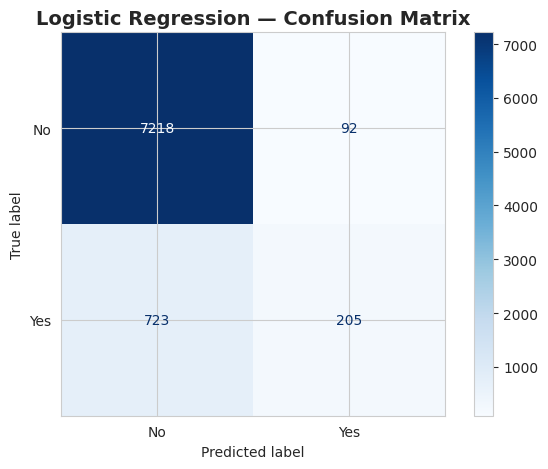

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

logistic_predictions = (
    logistic_probability >= logistic_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title(
    "Logistic Regression — Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
show_scoreboard()

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.5,0.901068,0.690236,0.220905,0.334694,0.800771,0.466325


In [ ]:
import mlflow

with mlflow.start_run(run_name="Logistic_Regression_Baseline"):

    # -----------------------------
    # Parameters
    # -----------------------------
    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("C", 1.0)
    mlflow.log_param("solver", "liblinear")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("class_weight", "None")
    mlflow.log_param("random_state", 42)
    mlflow.log_param("threshold", 0.50)

    # -----------------------------
    # Train
    # -----------------------------
    logistic_pipeline.fit(X_train, y_train)

    # -----------------------------
    # Probability prediction
    # -----------------------------
    y_prob_lr = logistic_pipeline.predict_proba(X_test)[:, 1]

    # -----------------------------
    # Apply baseline threshold
    # -----------------------------
    y_pred_lr = (y_prob_lr >= 0.50).astype(int)

    # -----------------------------
    # Metrics
    # -----------------------------
    lr_accuracy = accuracy_score(y_test, y_pred_lr)
    lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
    lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
    lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
    lr_roc_auc = roc_auc_score(y_test, y_prob_lr)
    lr_pr_auc = average_precision_score(y_test, y_prob_lr)

    # -----------------------------
    # Log metrics
    # -----------------------------
    mlflow.log_metric("accuracy", lr_accuracy)
    mlflow.log_metric("precision", lr_precision)
    mlflow.log_metric("recall", lr_recall)
    mlflow.log_metric("f1", lr_f1)
    mlflow.log_metric("roc_auc", lr_roc_auc)
    mlflow.log_metric("pr_auc", lr_pr_auc)

    print("✅ Logistic Regression logged to MLflow")

✅ Logistic Regression logged to MLflow


### BOX 18 — Random Forest

Random Forest is our second model.

Unlike Logistic Regression, Random Forest is a tree-based ensemble model and does not require feature scaling.

For this model, I will therefore use:

- One-hot encoding for categorical variables
- Original numerical values without standardization
- Random Forest classifier
- Probability threshold of 0.50 for the baseline comparison

The model parameters and evaluation results will be recorded in MLflow and in the common model scoreboard.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Random Forest preprocessing created.")

Random Forest preprocessing created.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_params = {
    "n_estimators": 300,
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "class_weight": None,
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

print("Random Forest parameters:")
display(pd.DataFrame(
    list(rf_params.items()),
    columns=["Parameter", "Value"]
))

Random Forest parameters:


,Parameter,Value
0,n_estimators,300
1,max_depth,None
2,min_samples_split,2
3,min_samples_leaf,1
4,max_features,sqrt
5,class_weight,None
6,random_state,42
7,n_jobs,-1


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=rf_params["n_estimators"],
    max_depth=rf_params["max_depth"],
    min_samples_split=rf_params["min_samples_split"],
    min_samples_leaf=rf_params["min_samples_leaf"],
    max_features=rf_params["max_features"],
    class_weight=rf_params["class_weight"],
    random_state=rf_params["random_state"],
    n_jobs=rf_params["n_jobs"]
)

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("model", rf_model)
    ]
)

print("Random Forest pipeline created.")

Random Forest pipeline created.


In [ ]:
with mlflow.start_run(run_name="Random_Forest_Baseline"):

    # -----------------------------
    # Log parameters
    # -----------------------------
    mlflow.log_param("model", "Random Forest")

    for param_name, param_value in rf_params.items():
        mlflow.log_param(param_name, str(param_value))

    mlflow.log_param("threshold", 0.50)

    # -----------------------------
    # Train
    # -----------------------------
    rf_pipeline.fit(X_train, y_train)

    # -----------------------------
    # Probability prediction
    # -----------------------------
    y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

    # -----------------------------
    # Baseline threshold
    # -----------------------------
    rf_threshold = 0.50

    y_pred_rf = (
        y_prob_rf >= rf_threshold
    ).astype(int)

    # -----------------------------
    # Metrics
    # -----------------------------
    rf_accuracy = accuracy_score(y_test, y_pred_rf)
    rf_precision = precision_score(
        y_test, y_pred_rf, zero_division=0
    )
    rf_recall = recall_score(
        y_test, y_pred_rf, zero_division=0
    )
    rf_f1 = f1_score(
        y_test, y_pred_rf, zero_division=0
    )
    rf_roc_auc = roc_auc_score(
        y_test, y_prob_rf
    )
    rf_pr_auc = average_precision_score(
        y_test, y_prob_rf
    )

    # -----------------------------
    # Log metrics
    # -----------------------------
    mlflow.log_metric("accuracy", rf_accuracy)
    mlflow.log_metric("precision", rf_precision)
    mlflow.log_metric("recall", rf_recall)
    mlflow.log_metric("f1", rf_f1)
    mlflow.log_metric("roc_auc", rf_roc_auc)
    mlflow.log_metric("pr_auc", rf_pr_auc)

    print(" Random Forest logged to MLflow")

 Random Forest logged to MLflow


In [ ]:
rf_result = {
    "Model": "Random Forest",
    "Threshold": rf_threshold,
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1": rf_f1,
    "ROC-AUC": rf_roc_auc,
    "PR-AUC": rf_pr_auc
}

model_results.append(rf_result)

display(
    pd.DataFrame(model_results)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.5,0.894635,0.561224,0.296336,0.387870,0.787512,0.435896
1,Logistic Regression,0.5,0.901068,0.690236,0.220905,0.334694,0.800771,0.466325


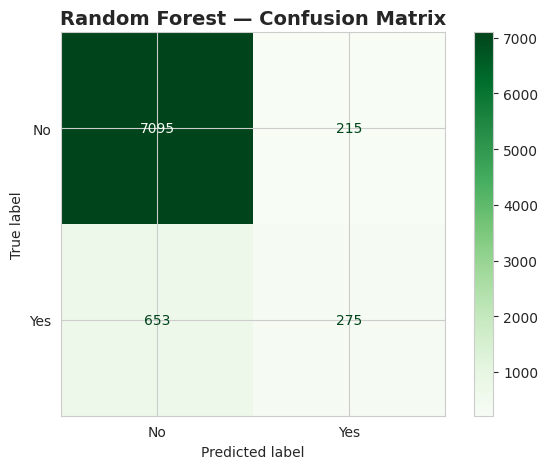

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No", "Yes"],
    cmap="Greens"
)

plt.title(
    "Random Forest — Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Key Insight

Random Forest provides a second benchmark against Logistic Regression.

Since this is a tree-based model, feature scaling was not required. The model can capture non-linear relationships and interactions between variables that a linear model may not capture as effectively.

The model will be compared with Logistic Regression using the same evaluation metrics and the same baseline probability threshold of 0.50.

For Random Forest, I don't need standardization because tree-based models don't depend on the distance or magnitude of the features in the same way as Logistic Regression. I'm keeping the baseline threshold at 0.50 so the comparison remains fair

### BOX 19 — XGBoost

XGBoost is the third model in the comparison.

It is a gradient-boosting algorithm that builds decision trees sequentially, where each new tree attempts to improve the errors made by the previous trees.

For the baseline experiment, I will use:

- One-hot encoding for categorical variables
- No feature scaling
- XGBoost classifier
- Probability threshold = 0.50

The parameters used for this experiment will be recorded explicitly in both the notebook and MLflow.

In [ ]:
from xgboost import XGBClassifier

print("XGBoost imported successfully.")

XGBoost imported successfully.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("XGBoost preprocessing created.")

XGBoost preprocessing created.


In [ ]:
xgb_params = {
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 1,
    "gamma": 0,
    "reg_alpha": 0,
    "reg_lambda": 1,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "eval_metric": "logloss"
}

print("XGBoost parameters:")
display(pd.DataFrame(
    list(xgb_params.items()),
    columns=["Parameter", "Value"]
))

XGBoost parameters:


,Parameter,Value
0,n_estimators,300
1,max_depth,6
2,learning_rate,0.1
3,subsample,0.8
4,colsample_bytree,0.8
5,min_child_weight,1
6,gamma,0
7,reg_alpha,0
8,reg_lambda,1
9,random_state,42


In [ ]:
xgb_model = XGBClassifier(
    **xgb_params
)

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", xgb_preprocessor),
        ("model", xgb_model)
    ]
)

print("XGBoost pipeline created.")

XGBoost pipeline created.


In [ ]:
xgb_threshold = 0.240

with mlflow.start_run(run_name="XGBoost_Baseline"):

    # -----------------------------
    # Log model parameters
    # -----------------------------
    mlflow.log_param("model", "XGBoost")

    for param_name, param_value in xgb_params.items():
        mlflow.log_param(
            param_name,
            str(param_value)
        )

    mlflow.log_param(
        "threshold",
        xgb_threshold
    )

    # -----------------------------
    # Train
    # -----------------------------
    xgb_pipeline.fit(
        X_train,
        y_train
    )

    # -----------------------------
    # Probability prediction
    # -----------------------------
    y_prob_xgb = (
        xgb_pipeline.predict_proba(X_test)[:, 1]
    )

    # -----------------------------
    # Apply baseline threshold
    # -----------------------------
    y_pred_xgb = (
        y_prob_xgb >= xgb_threshold
    ).astype(int)

    # -----------------------------
    # Metrics
    # -----------------------------
    xgb_accuracy = accuracy_score(
        y_test,
        y_pred_xgb
    )

    xgb_precision = precision_score(
        y_test,
        y_pred_xgb,
        zero_division=0
    )

    xgb_recall = recall_score(
        y_test,
        y_pred_xgb,
        zero_division=0
    )

    xgb_f1 = f1_score(
        y_test,
        y_pred_xgb,
        zero_division=0
    )

    xgb_roc_auc = roc_auc_score(
        y_test,
        y_prob_xgb
    )

    xgb_pr_auc = average_precision_score(
        y_test,
        y_prob_xgb
    )

    # -----------------------------
    # Log metrics
    # -----------------------------
    mlflow.log_metric("accuracy", xgb_accuracy)
    mlflow.log_metric("precision", xgb_precision)
    mlflow.log_metric("recall", xgb_recall)
    mlflow.log_metric("f1", xgb_f1)
    mlflow.log_metric("roc_auc", xgb_roc_auc)
    mlflow.log_metric("pr_auc", xgb_pr_auc)

    print(" XGBoost logged to MLflow.")

 XGBoost logged to MLflow.


In [ ]:
xgb_result = {
    "Model": "XGBoost",
    "Threshold": xgb_threshold,
    "Accuracy": xgb_accuracy,
    "Precision": xgb_precision,
    "Recall": xgb_recall,
    "F1": xgb_f1,
    "ROC-AUC": xgb_roc_auc,
    "PR-AUC": xgb_pr_auc
}

model_results.append(xgb_result)

scoreboard = (
    pd.DataFrame(model_results)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(scoreboard)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,0.24,0.887715,0.501505,0.538793,0.519481,0.799766,0.470569
1,Random Forest,0.50,0.894635,0.561224,0.296336,0.387870,0.787512,0.435896
2,Logistic Regression,0.50,0.901068,0.690236,0.220905,0.334694,0.800771,0.466325


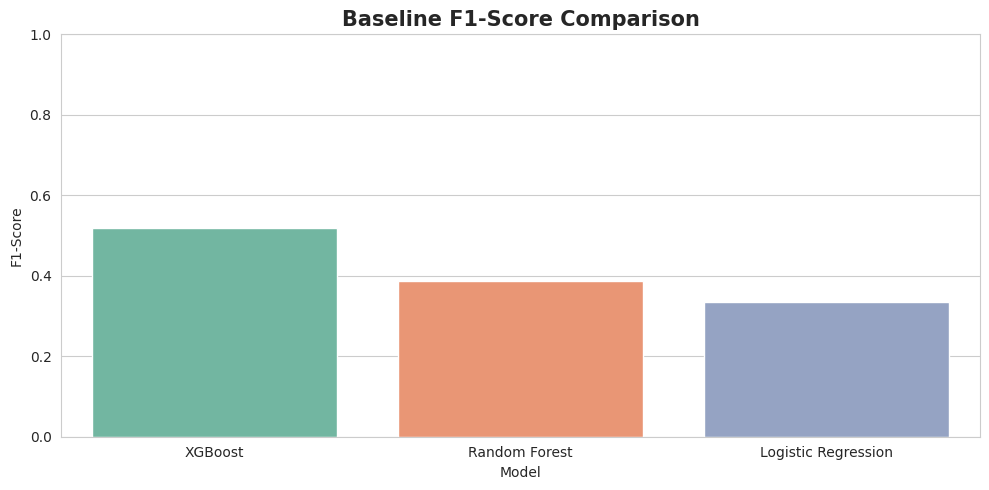

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=scoreboard,
    x="Model",
    y="F1",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title(
    "Baseline F1-Score Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("F1-Score")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

#### Key Insight

XGBoost has now been evaluated using the same baseline threshold of 0.50 used for the previous models.

At this stage, I am not declaring XGBoost as the final model even if it gives the best score.

The remaining CatBoost and LightGBM models still need to be evaluated before selecting the model for optimization.

XGBoost was one of the strongest models in my previous experimentation, but I'm not assuming that result here. I'm rebuilding the comparison from the beginning using the same dataset split, preprocessing logic and baseline threshold. Once CatBoost and LightGBM are also tested, we'll have a fair comparison

### BOX 20 — CatBoost

CatBoost is the fourth model in the comparison.

Unlike the previous models, CatBoost can work directly with categorical features. Therefore, I will keep the categorical columns in their original form instead of one-hot encoding them.

For this baseline experiment:

- Numerical features will be kept as numerical values.
- Categorical features will be passed directly to CatBoost.
- No feature scaling is required.
- The baseline probability threshold will remain 0.50.
- The exact model parameters will be recorded in MLflow.

In [ ]:
from catboost import CatBoostClassifier

print("CatBoost imported successfully.")

CatBoost imported successfully.


In [ ]:
# Copy the train and test data
X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

# CatBoost requires categorical column indices
cat_feature_indices = [
    X_train_cb.columns.get_loc(col)
    for col in categorical_features
]

print("Number of categorical features:", len(cat_feature_indices))
print("Categorical feature indices:", cat_feature_indices)

Number of categorical features: 10
Categorical feature indices: [1, 2, 3, 4, 5, 6, 7, 8, 9, 13]


In [ ]:
catboost_params = {
    "iterations": 300,
    "depth": 6,
    "learning_rate": 0.1,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": RANDOM_STATE,
    "verbose": False,
    "thread_count": -1
}

print("CatBoost parameters:")
display(pd.DataFrame(
    list(catboost_params.items()),
    columns=["Parameter", "Value"]
))

CatBoost parameters:


,Parameter,Value
0,iterations,300
1,depth,6
2,learning_rate,0.1
3,loss_function,Logloss
4,eval_metric,AUC
5,random_seed,42
6,verbose,False
7,thread_count,-1


In [ ]:
catboost_model = CatBoostClassifier(
    **catboost_params
)

print("CatBoost model created.")

CatBoost model created.


In [ ]:
catboost_threshold = 0.50

with mlflow.start_run(run_name="CatBoost_Baseline"):

    # -----------------------------
    # Log parameters
    # -----------------------------
    mlflow.log_param("model", "CatBoost")

    for param_name, param_value in catboost_params.items():
        mlflow.log_param(
            param_name,
            str(param_value)
        )

    mlflow.log_param(
        "threshold",
        catboost_threshold
    )

    # -----------------------------
    # Train
    # -----------------------------
    catboost_model.fit(
        X_train_cb,
        y_train,
        cat_features=cat_feature_indices
    )

    # -----------------------------
    # Probability prediction
    # -----------------------------
    y_prob_cb = catboost_model.predict_proba(
        X_test_cb
    )[:, 1]

    # -----------------------------
    # Baseline threshold
    # -----------------------------
    y_pred_cb = (
        y_prob_cb >= catboost_threshold
    ).astype(int)

    # -----------------------------
    # Metrics
    # -----------------------------
    cb_accuracy = accuracy_score(
        y_test,
        y_pred_cb
    )

    cb_precision = precision_score(
        y_test,
        y_pred_cb,
        zero_division=0
    )

    cb_recall = recall_score(
        y_test,
        y_pred_cb,
        zero_division=0
    )

    cb_f1 = f1_score(
        y_test,
        y_pred_cb,
        zero_division=0
    )

    cb_roc_auc = roc_auc_score(
        y_test,
        y_prob_cb
    )

    cb_pr_auc = average_precision_score(
        y_test,
        y_prob_cb
    )

    # -----------------------------
    # Log metrics
    # -----------------------------
    mlflow.log_metric("accuracy", cb_accuracy)
    mlflow.log_metric("precision", cb_precision)
    mlflow.log_metric("recall", cb_recall)
    mlflow.log_metric("f1", cb_f1)
    mlflow.log_metric("roc_auc", cb_roc_auc)
    mlflow.log_metric("pr_auc", cb_pr_auc)

    print(" CatBoost logged to MLflow.")

 CatBoost logged to MLflow.


In [ ]:
catboost_result = {
    "Model": "CatBoost",
    "Threshold": catboost_threshold,
    "Accuracy": cb_accuracy,
    "Precision": cb_precision,
    "Recall": cb_recall,
    "F1": cb_f1,
    "ROC-AUC": cb_roc_auc,
    "PR-AUC": cb_pr_auc
}

model_results.append(catboost_result)

scoreboard = (
    pd.DataFrame(model_results)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(scoreboard)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,0.24,0.887715,0.501505,0.538793,0.519481,0.799766,0.470569
1,Random Forest,0.50,0.894635,0.561224,0.296336,0.387870,0.787512,0.435896
2,CatBoost,0.50,0.902282,0.661417,0.271552,0.385027,0.813511,0.487621
3,Logistic Regression,0.50,0.901068,0.690236,0.220905,0.334694,0.800771,0.466325


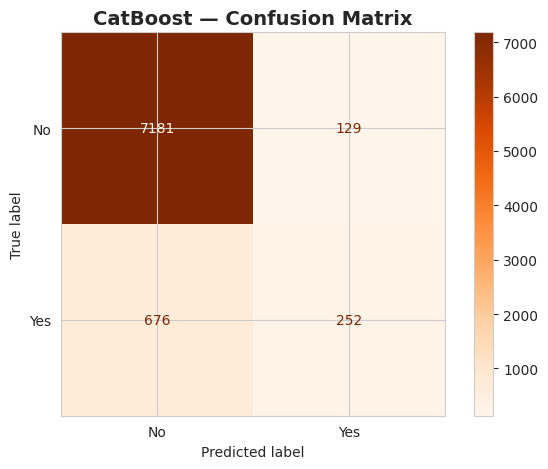

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_cb,
    display_labels=["No", "Yes"],
    cmap="Oranges"
)

plt.title(
    "CatBoost — Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

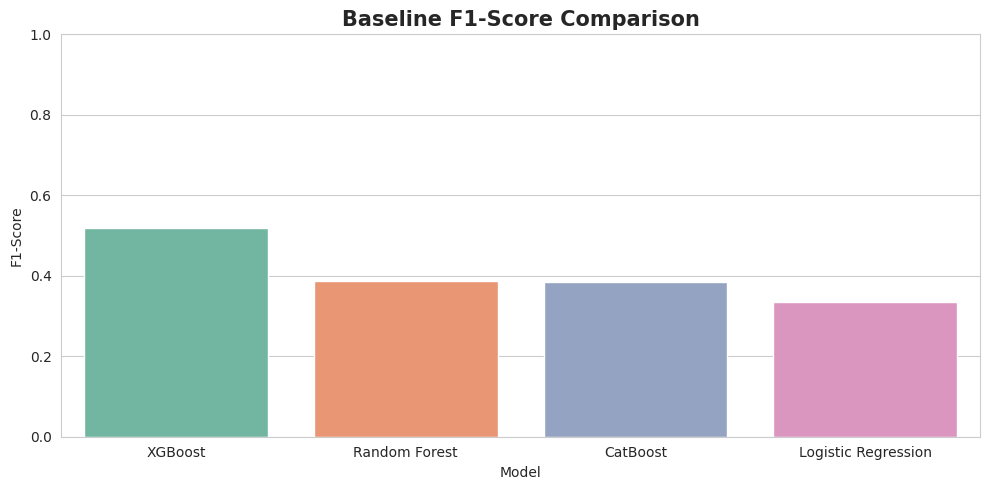

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=scoreboard,
    x="Model",
    y="F1",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title(
    "Baseline F1-Score Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

#### Key Insight

CatBoost uses the categorical variables directly rather than converting them into one-hot encoded columns.

This gives us a useful comparison with the previous models because the algorithm is able to learn from categorical variables using its own categorical-feature handling.

The model is still being evaluated at the common baseline threshold of 0.50. No threshold optimization has been performed yet.

CatBoost is slightly different from the previous models. Instead of one-hot encoding the categorical variables, I'm allowing CatBoost to handle them directly. This is one of the reasons I wanted to include CatBoost in the comparison.

### BOX 21 — LightGBM

LightGBM is the fifth and final model in the baseline comparison.

It is another gradient-boosting algorithm, but it uses a different tree-building strategy from XGBoost.

For a fair baseline comparison, I will use:

- One-hot encoding for categorical variables
- No feature scaling
- LightGBM classifier
- Probability threshold = 0.50

The exact parameters and evaluation metrics will be recorded in MLflow and in the common model scoreboard.

In [ ]:
from lightgbm import LGBMClassifier

print("LightGBM imported successfully.")

LightGBM imported successfully.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

lgbm_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("LightGBM preprocessing created.")

LightGBM preprocessing created.


In [ ]:
lgbm_params = {
    "n_estimators": 300,
    "max_depth": -1,
    "num_leaves": 31,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0,
    "reg_lambda": 0,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbosity": -1
}

print("LightGBM parameters:")
display(pd.DataFrame(
    list(lgbm_params.items()),
    columns=["Parameter", "Value"]
))

LightGBM parameters:


,Parameter,Value
0,n_estimators,300.0
1,max_depth,-1.0
2,num_leaves,31.0
3,learning_rate,0.1
4,subsample,0.8
5,colsample_bytree,0.8
6,reg_alpha,0.0
7,reg_lambda,0.0
8,random_state,42.0
9,n_jobs,-1.0


In [ ]:
lgbm_model = LGBMClassifier(
    **lgbm_params
)

lgbm_pipeline = Pipeline(
    steps=[
        ("preprocessor", lgbm_preprocessor),
        ("model", lgbm_model)
    ]
)

print("LightGBM pipeline created.")

LightGBM pipeline created.


In [ ]:
lgbm_threshold = 0.50

with mlflow.start_run(run_name="LightGBM_Baseline"):

    # -----------------------------
    # Log parameters
    # -----------------------------
    mlflow.log_param("model", "LightGBM")

    for param_name, param_value in lgbm_params.items():
        mlflow.log_param(
            param_name,
            str(param_value)
        )

    mlflow.log_param(
        "threshold",
        lgbm_threshold
    )

    # -----------------------------
    # Train
    # -----------------------------
    lgbm_pipeline.fit(
        X_train,
        y_train
    )

    # -----------------------------
    # Probability prediction
    # -----------------------------
    y_prob_lgbm = (
        lgbm_pipeline.predict_proba(X_test)[:, 1]
    )

    # -----------------------------
    # Baseline threshold
    # -----------------------------
    y_pred_lgbm = (
        y_prob_lgbm >= lgbm_threshold
    ).astype(int)

    # -----------------------------
    # Metrics
    # -----------------------------
    lgbm_accuracy = accuracy_score(
        y_test,
        y_pred_lgbm
    )

    lgbm_precision = precision_score(
        y_test,
        y_pred_lgbm,
        zero_division=0
    )

    lgbm_recall = recall_score(
        y_test,
        y_pred_lgbm,
        zero_division=0
    )

    lgbm_f1 = f1_score(
        y_test,
        y_pred_lgbm,
        zero_division=0
    )

    lgbm_roc_auc = roc_auc_score(
        y_test,
        y_prob_lgbm
    )

    lgbm_pr_auc = average_precision_score(
        y_test,
        y_prob_lgbm
    )

    # -----------------------------
    # Log metrics
    # -----------------------------
    mlflow.log_metric("accuracy", lgbm_accuracy)
    mlflow.log_metric("precision", lgbm_precision)
    mlflow.log_metric("recall", lgbm_recall)
    mlflow.log_metric("f1", lgbm_f1)
    mlflow.log_metric("roc_auc", lgbm_roc_auc)
    mlflow.log_metric("pr_auc", lgbm_pr_auc)

    print(" LightGBM logged to MLflow.")

 LightGBM logged to MLflow.


In [ ]:
lgbm_result = {
    "Model": "LightGBM",
    "Threshold": lgbm_threshold,
    "Accuracy": lgbm_accuracy,
    "Precision": lgbm_precision,
    "Recall": lgbm_recall,
    "F1": lgbm_f1,
    "ROC-AUC": lgbm_roc_auc,
    "PR-AUC": lgbm_pr_auc
}

model_results.append(lgbm_result)

scoreboard = (
    pd.DataFrame(model_results)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(scoreboard)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,0.24,0.887715,0.501505,0.538793,0.519481,0.799766,0.470569
1,LightGBM,0.50,0.902161,0.645933,0.290948,0.401189,0.806594,0.486874
2,Random Forest,0.50,0.894635,0.561224,0.296336,0.387870,0.787512,0.435896
3,CatBoost,0.50,0.902282,0.661417,0.271552,0.385027,0.813511,0.487621
4,Logistic Regression,0.50,0.901068,0.690236,0.220905,0.334694,0.800771,0.466325


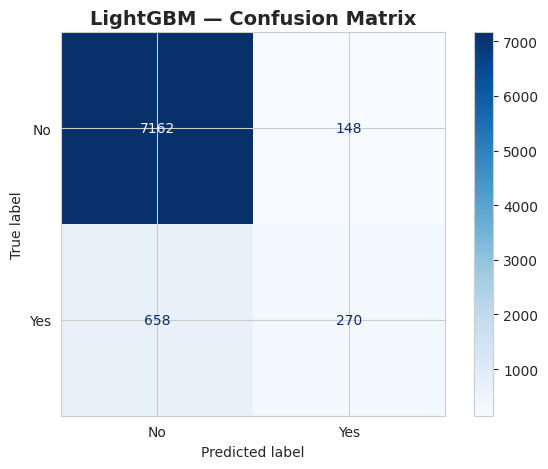

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lgbm,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title(
    "LightGBM — Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

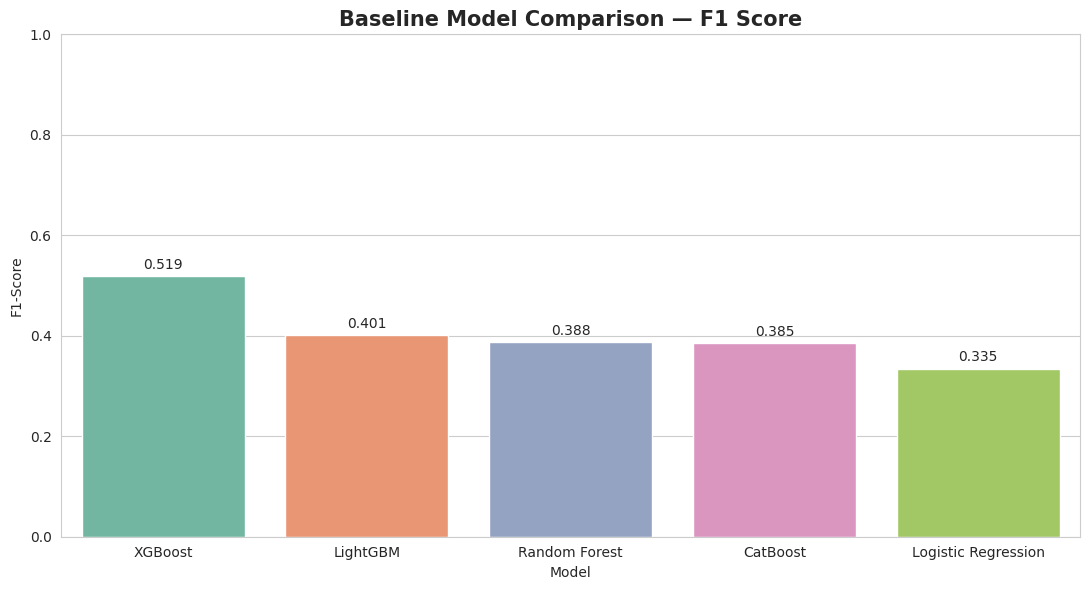

In [ ]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=scoreboard,
    x="Model",
    y="F1",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title(
    "Baseline Model Comparison — F1 Score",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.ylim(0, 1)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.tight_layout()
plt.show()

####  Key Insight

All five models have now been trained and evaluated using the same baseline probability threshold of 0.50.

At this stage, the models can be compared using their:

- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

The model with the strongest overall performance will be selected for the next stage.

Importantly, no threshold optimization has been performed yet. This keeps the initial model comparison consistent.

LightGBM completes our initial five-model comparison. All five models were evaluated using the same test set and the same 0.50 probability threshold. Now I can compare them objectively rather than assuming XGBoost is the best model based on my earlier experiments

### BOX 22 — Threshold Analysis

The default classification threshold of 0.50 is not necessarily the best threshold for this business problem.

Instead of assuming that 0.50 is optimal, I will evaluate different probability thresholds for each of the five models.

I will test thresholds from **0.01 to 0.71, using increments of 0.005.

For every model, I will record:

- Threshold
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

This gives approximately 15 threshold combinations for each model.

The threshold analysis will be performed on a validation set created from the training data. The original test set will remain untouched and will only be used for the final evaluation.

Two selection perspectives will then be considered:

###  F1-Focused
Prioritizes a balance between precision and recall.

### Recall-Focused
Prioritizes identifying as many potential subscribers as possible, even if this results in more false positives.

The top three threshold results from each model will be retained for both strategies.

Finally, these results will be combined and sorted to identify the strongest threshold-model combinations.

In [ ]:
from sklearn.model_selection import train_test_split

# Create validation set from the training data
X_model_train, X_validation, y_model_train, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Model training set :", X_model_train.shape)
print("Validation set     :", X_validation.shape)
print("Final test set     :", X_test.shape)

Model training set : (26360, 25)
Validation set     : (6590, 25)
Final test set     : (8238, 25)


In [ ]:
thresholds = np.round(
    np.arange(0.01, 0.71, 0.005),
    2
)

print("Thresholds:")
print(thresholds)

print("\nNumber of thresholds:", len(thresholds))

Thresholds:
[0.01 0.02 0.02 0.02 0.03 0.03 0.04 0.04 0.05 0.05 0.06 0.06 0.07 0.07
 0.08 0.08 0.09 0.09 0.1  0.1  0.11 0.11 0.12 0.12 0.13 0.13 0.14 0.14
 0.15 0.16 0.16 0.16 0.17 0.18 0.18 0.18 0.19 0.19 0.2  0.2  0.21 0.21
 0.22 0.22 0.23 0.24 0.24 0.24 0.25 0.25 0.26 0.26 0.27 0.27 0.28 0.28
 0.29 0.3  0.3  0.3  0.31 0.31 0.32 0.32 0.33 0.34 0.34 0.34 0.35 0.36
 0.36 0.36 0.37 0.37 0.38 0.38 0.39 0.39 0.4  0.4  0.41 0.41 0.42 0.42
 0.43 0.43 0.44 0.44 0.45 0.45 0.46 0.46 0.47 0.47 0.48 0.48 0.49 0.49
 0.5  0.5  0.51 0.51 0.52 0.52 0.53 0.53 0.54 0.54 0.55 0.55 0.56 0.56
 0.57 0.57 0.58 0.58 0.59 0.6  0.6  0.6  0.61 0.61 0.62 0.62 0.63 0.63
 0.64 0.64 0.65 0.65 0.66 0.66 0.67 0.68 0.68 0.68 0.69 0.7  0.7  0.7 ]

Number of thresholds: 140


In [ ]:
def threshold_scan(
    model_name,
    y_true,
    y_probability,
    thresholds
):
    """
    Evaluate one model across multiple probability thresholds.
    """

    results = []

    roc_auc = roc_auc_score(y_true, y_probability)
    pr_auc = average_precision_score(y_true, y_probability)

    for threshold in thresholds:

        # Convert probability to class prediction
        y_pred = (
            y_probability >= threshold
        ).astype(int)

        # Calculate metrics
        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        precision = precision_score(
            y_true,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_true,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            y_pred,
            zero_division=0
        )

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC-AUC": roc_auc,
            "PR-AUC": pr_auc
        })

    return pd.DataFrame(results)

### BOX 23 — Logistic Regression Threshold Analysis

Logistic Regression is used as the linear baseline for the model comparison.

To keep the comparison consistent, the model uses the same 25-feature engineered representation:

- 19 original features
- 6 engineered features
- Total = 25 features

The five engineered features are:

- `total_contact_history`
- `contact_timing_history`
- `economic_rate_pressure`
- `employment_economic_pressure`
- `consumer_economic_index`

The `previously_contacted` feature is included in this experiment.

Since Logistic Regression is sensitive to feature scale, numerical variables will be standardized while categorical variables will be one-hot encoded.

The probability threshold will then be varied from 0.01 to 0.71 to study the precision-recall trade-off.

In [ ]:
X_lr = X.copy()

X_lr["total_contact_history"] = (
    X_lr["campaign"] + X_lr["previous"]
)

X_lr["contact_timing_history"] = (
    X_lr["pdays"] * (X_lr["previous"] + 1)
)

X_lr["economic_rate_pressure"] = (
    X_lr["emp.var.rate"] + X_lr["euribor3m"]
)

X_lr["employment_economic_pressure"] = (
    X_lr["emp.var.rate"] + X_lr["nr.employed"]
)

X_lr["consumer_economic_index"] = (
    X_lr["cons.price.idx"] + X_lr["cons.conf.idx"]
)

print("Logistic Regression feature count:", X_lr.shape[1])

Logistic Regression feature count: 25


In [ ]:
X_lr_train, X_lr_validation, y_lr_train, y_lr_validation = (
    train_test_split(
        X_lr,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("Logistic Regression training shape  :", X_lr_train.shape)
print("Logistic Regression validation shape:", X_lr_validation.shape)

Logistic Regression training shape  : (32950, 25)
Logistic Regression validation shape: (8238, 25)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_lr = X_lr_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_lr = X_lr_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

lr_threshold_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_lr
        ),
        (
            "num",
            StandardScaler(),
            numerical_lr
        )
    ]
)

X_lr_train_encoded = (
    lr_threshold_preprocessor.fit_transform(
        X_lr_train
    )
)

X_lr_validation_encoded = (
    lr_threshold_preprocessor.transform(
        X_lr_validation
    )
)

print(
    "Logical features:",
    X_lr.shape[1]
)

print(
    "Encoded training columns:",
    X_lr_train_encoded.shape[1]
)

print(
    "Encoded validation columns:",
    X_lr_validation_encoded.shape[1]
)

Logical features: 25
Encoded training columns: 68
Encoded validation columns: 68


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_threshold_params = {
    "C": 1.0,
    "solver": "liblinear",
    "max_iter": 1000,
    "class_weight": "balanced",
    "random_state": 42
}

display(
    pd.DataFrame(
        list(lr_threshold_params.items()),
        columns=["Parameter", "Value"]
    )
)

,Parameter,Value
0,C,1.0
1,solver,liblinear
2,max_iter,1000
3,class_weight,balanced
4,random_state,42


In [ ]:
lr_threshold_model = LogisticRegression(
    **lr_threshold_params
)

lr_threshold_model.fit(
    X_lr_train_encoded,
    y_lr_train
)

print("Logistic Regression training completed successfully.")

Logistic Regression training completed successfully.


In [ ]:
lr_validation_prob = (
    lr_threshold_model
    .predict_proba(
        X_lr_validation_encoded
    )[:, 1]
)

print("Validation probabilities generated.")
print(
    "Number of predictions:",
    len(lr_validation_prob)
)

Validation probabilities generated.
Number of predictions: 8238


In [ ]:
lr_threshold_results = threshold_scan(
    model_name="Logistic Regression",
    y_true=y_lr_validation,
    y_probability=lr_validation_prob,
    thresholds=thresholds
)

display(
    lr_threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
130,Logistic Regression,0.66,0.873877,0.453479,0.582974,0.510137,0.800845,0.461585
131,Logistic Regression,0.66,0.873877,0.453479,0.582974,0.510137,0.800845,0.461585
132,Logistic Regression,0.67,0.876548,0.461203,0.570043,0.509880,0.800845,0.461585
128,Logistic Regression,0.65,0.870600,0.444534,0.595905,0.509208,0.800845,0.461585
129,Logistic Regression,0.65,0.870600,0.444534,0.595905,0.509208,0.800845,0.461585
125,Logistic Regression,0.63,0.865380,0.431387,0.613147,0.506453,0.800845,0.461585
124,Logistic Regression,0.63,0.865380,0.431387,0.613147,0.506453,0.800845,0.461585
127,Logistic Regression,0.64,0.867444,0.435937,0.601293,0.505435,0.800845,0.461585
126,Logistic Regression,0.64,0.867444,0.435937,0.601293,0.505435,0.800845,0.461585
123,Logistic Regression,0.62,0.863195,0.426132,0.618534,0.504615,0.800845,0.461585


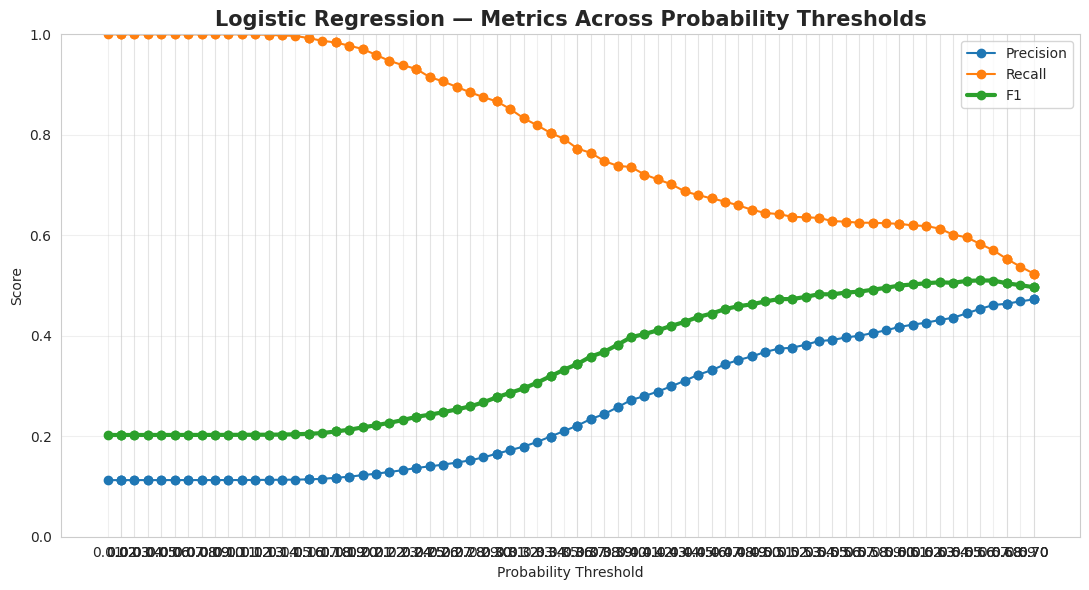

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(
    lr_threshold_results["Threshold"],
    lr_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    lr_threshold_results["Threshold"],
    lr_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    lr_threshold_results["Threshold"],
    lr_threshold_results["F1"],
    marker="o",
    linewidth=3,
    label="F1"
)

plt.title(
    "Logistic Regression — Metrics Across Probability Thresholds",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")

plt.xticks(thresholds)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### BOX 24 — Random Forest Threshold Analysis

Random Forest is the second model in the threshold analysis.

To maintain consistency with the other model experiments, Random Forest will use the same 25-feature engineered dataset:

- 19 original features
- 6 engineered features
- Total = 25 features

The five engineered features are:

- `total_contact_history`
- `contact_timing_history`
- `economic_rate_pressure`
- `employment_economic_pressure`
- `consumer_economic_index`

The `previously_contacted` feature is included in this 25-feature experiment.

Since Random Forest is a tree-based model, numerical feature scaling is not required.

The model parameters will remain fixed while probability thresholds from 0.01 to 0.71 are evaluated.

In [ ]:
# Start with the 19 original features
X_rf = X.copy()

# Add the five engineered features

X_rf["total_contact_history"] = (
    X_rf["campaign"] + X_rf["previous"]
)

X_rf["contact_timing_history"] = (
    X_rf["pdays"] * (X_rf["previous"] + 1)
)

X_rf["economic_rate_pressure"] = (
    X_rf["emp.var.rate"] + X_rf["euribor3m"]
)

X_rf["employment_economic_pressure"] = (
    X_rf["emp.var.rate"] + X_rf["nr.employed"]
)

X_rf["consumer_economic_index"] = (
    X_rf["cons.price.idx"] + X_rf["cons.conf.idx"]
)

print("Random Forest feature count:", X_rf.shape[1])

Random Forest feature count: 25


In [ ]:
from sklearn.model_selection import train_test_split

X_rf_train, X_rf_validation, y_rf_train, y_rf_validation = (
    train_test_split(
        X_rf,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("Random Forest training shape  :", X_rf_train.shape)
print("Random Forest validation shape:", X_rf_validation.shape)

Random Forest training shape  : (32950, 25)
Random Forest validation shape: (8238, 25)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_rf = X_rf_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_rf = X_rf_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

rf_threshold_encoder = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_rf
        ),
        (
            "num",
            "passthrough",
            numerical_rf
        )
    ]
)

X_rf_train_encoded = (
    rf_threshold_encoder.fit_transform(
        X_rf_train
    )
)

X_rf_validation_encoded = (
    rf_threshold_encoder.transform(
        X_rf_validation
    )
)

print(
    "Logical features:",
    X_rf.shape[1]
)

print(
    "Encoded training columns:",
    X_rf_train_encoded.shape[1]
)

print(
    "Encoded validation columns:",
    X_rf_validation_encoded.shape[1]
)

Logical features: 25
Encoded training columns: 68
Encoded validation columns: 68


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_threshold_params = {
    "n_estimators": 500,
    "max_depth": 12,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": -1
}

display(
    pd.DataFrame(
        list(rf_threshold_params.items()),
        columns=["Parameter", "Value"]
    )
)

,Parameter,Value
0,n_estimators,500
1,max_depth,12
2,min_samples_split,5
3,min_samples_leaf,2
4,max_features,sqrt
5,class_weight,balanced
6,random_state,42
7,n_jobs,-1


In [ ]:
rf_threshold_model = RandomForestClassifier(
    **rf_threshold_params
)

rf_threshold_model.fit(
    X_rf_train_encoded,
    y_rf_train
)

print("Random Forest training completed successfully.")

Random Forest training completed successfully.


In [ ]:
rf_validation_prob = (
    rf_threshold_model
    .predict_proba(
        X_rf_validation_encoded
    )[:, 1]
)

print("Validation probabilities generated.")
print(
    "Number of predictions:",
    len(rf_validation_prob)
)

Validation probabilities generated.
Number of predictions: 8238


In [ ]:
rf_threshold_results = threshold_scan(
    model_name="Random Forest",
    y_true=y_rf_validation,
    y_probability=rf_validation_prob,
    thresholds=thresholds
)

display(
    rf_threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
124,Random Forest,0.63,0.890750,0.514000,0.553879,0.533195,0.81652,0.489672
125,Random Forest,0.63,0.890750,0.514000,0.553879,0.533195,0.81652,0.489672
121,Random Forest,0.61,0.888080,0.502868,0.566810,0.532928,0.81652,0.489672
120,Random Forest,0.61,0.888080,0.502868,0.566810,0.532928,0.81652,0.489672
119,Random Forest,0.60,0.886137,0.495345,0.573276,0.531469,0.81652,0.489672
117,Random Forest,0.60,0.886137,0.495345,0.573276,0.531469,0.81652,0.489672
118,Random Forest,0.60,0.886137,0.495345,0.573276,0.531469,0.81652,0.489672
129,Random Forest,0.65,0.893178,0.525263,0.537716,0.531416,0.81652,0.489672
128,Random Forest,0.65,0.893178,0.525263,0.537716,0.531416,0.81652,0.489672
122,Random Forest,0.62,0.888929,0.506379,0.556034,0.530046,0.81652,0.489672


#### Key Insight

The Random Forest results show how changing the classification threshold affects the balance between precision and recall.

Lower thresholds classify more customers as potential subscribers, which generally favors recall.

Higher thresholds make the model more selective and can improve precision while reducing recall.

The best threshold will therefore depend on whether the objective is to maximize balanced performance using F1-score or to prioritize identifying as many potential subscribers as possible using recall.

### BOX 25 — XGBoost Threshold Analysis

XGBoost previously produced strong results in this project, so it will be evaluated using the same 25-feature engineered representation.

The feature set consists of:

- 19 original features
- 6 engineered features
- Total = 25 features

The five engineered features are:

- `total_contact_history`
- `contact_timing_history`
- `economic_rate_pressure`
- `employment_economic_pressure`
- `consumer_economic_index`

The `previously_contacted` feature is included in this 25-feature experiment.

The XGBoost configuration from the earlier successful experiment is retained while different probability thresholds are evaluated.

Thresholds from 0.01 to 0.71 will be tested to understand the precision-recall trade-off.

In [ ]:
# Start with the 19 original features
X_xgb = X.copy()

# Add the five engineered features

X_xgb["total_contact_history"] = (
    X_xgb["campaign"] + X_xgb["previous"]
)

X_xgb["contact_timing_history"] = (
    X_xgb["pdays"] * (X_xgb["previous"] + 1)
)

X_xgb["economic_rate_pressure"] = (
    X_xgb["emp.var.rate"] + X_xgb["euribor3m"]
)

X_xgb["employment_economic_pressure"] = (
    X_xgb["emp.var.rate"] + X_xgb["nr.employed"]
)

X_xgb["consumer_economic_index"] = (
    X_xgb["cons.price.idx"] + X_xgb["cons.conf.idx"]
)

print("XGBoost feature count:", X_xgb.shape[1])

XGBoost feature count: 25


In [ ]:
from sklearn.model_selection import train_test_split

X_xgb_train, X_xgb_validation, y_xgb_train, y_xgb_validation = (
    train_test_split(
        X_xgb,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("XGBoost training shape  :", X_xgb_train.shape)
print("XGBoost validation shape:", X_xgb_validation.shape)

XGBoost training shape  : (32950, 25)
XGBoost validation shape: (8238, 25)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_xgb = X_xgb_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_xgb = X_xgb_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

xgb_threshold_encoder = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_xgb
        ),
        (
            "num",
            "passthrough",
            numerical_xgb
        )
    ]
)

X_xgb_train_encoded = (
    xgb_threshold_encoder.fit_transform(
        X_xgb_train
    )
)

X_xgb_validation_encoded = (
    xgb_threshold_encoder.transform(
        X_xgb_validation
    )
)

print(
    "Logical features:",
    X_xgb.shape[1]
)

print(
    "Encoded training columns:",
    X_xgb_train_encoded.shape[1]
)

print(
    "Encoded validation columns:",
    X_xgb_validation_encoded.shape[1]
)

Logical features: 25
Encoded training columns: 68
Encoded validation columns: 68


In [ ]:
from xgboost import XGBClassifier

xgb_threshold_params = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 5,
    "min_child_weight": 1,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "reg_alpha": 0,
    "reg_lambda": 1,
    # "scale_pos_weight": 1.25,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1
}

display(
    pd.DataFrame(
        list(xgb_threshold_params.items()),
        columns=["Parameter", "Value"]
    )
)

,Parameter,Value
0,n_estimators,500
1,learning_rate,0.05
2,max_depth,5
3,min_child_weight,1
4,subsample,0.9
5,colsample_bytree,0.9
6,reg_alpha,0
7,reg_lambda,1
8,objective,binary:logistic
9,eval_metric,logloss


In [ ]:
xgb_threshold_model = XGBClassifier(
    **xgb_threshold_params
)

xgb_threshold_model.fit(
    X_xgb_train_encoded,
    y_xgb_train
)

print("XGBoost training completed successfully.")

XGBoost training completed successfully.


In [ ]:
xgb_validation_prob = (
    xgb_threshold_model
    .predict_proba(
        X_xgb_validation_encoded
    )[:, 1]
)

print("Validation probabilities generated.")
print(
    "Number of predictions:",
    len(xgb_validation_prob)
)

Validation probabilities generated.
Number of predictions: 8238


In [ ]:
xgb_threshold_results = threshold_scan(
    model_name="XGBoost",
    y_true=y_xgb_validation,
    y_probability=xgb_validation_prob,
    thresholds=thresholds
)


display(
    xgb_threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
47,XGBoost,0.24,0.890022,0.510659,0.567888,0.537755,0.810354,0.49128
45,XGBoost,0.24,0.890022,0.510659,0.567888,0.537755,0.810354,0.49128
46,XGBoost,0.24,0.890022,0.510659,0.567888,0.537755,0.810354,0.49128
44,XGBoost,0.23,0.888322,0.503774,0.575431,0.537223,0.810354,0.49128
48,XGBoost,0.25,0.890993,0.514881,0.559267,0.536157,0.810354,0.49128
49,XGBoost,0.25,0.890993,0.514881,0.559267,0.536157,0.810354,0.49128
40,XGBoost,0.21,0.884802,0.490566,0.588362,0.535032,0.810354,0.49128
41,XGBoost,0.21,0.884802,0.490566,0.588362,0.535032,0.810354,0.49128
50,XGBoost,0.26,0.891843,0.518820,0.549569,0.533752,0.810354,0.49128
51,XGBoost,0.26,0.891843,0.518820,0.549569,0.533752,0.810354,0.49128


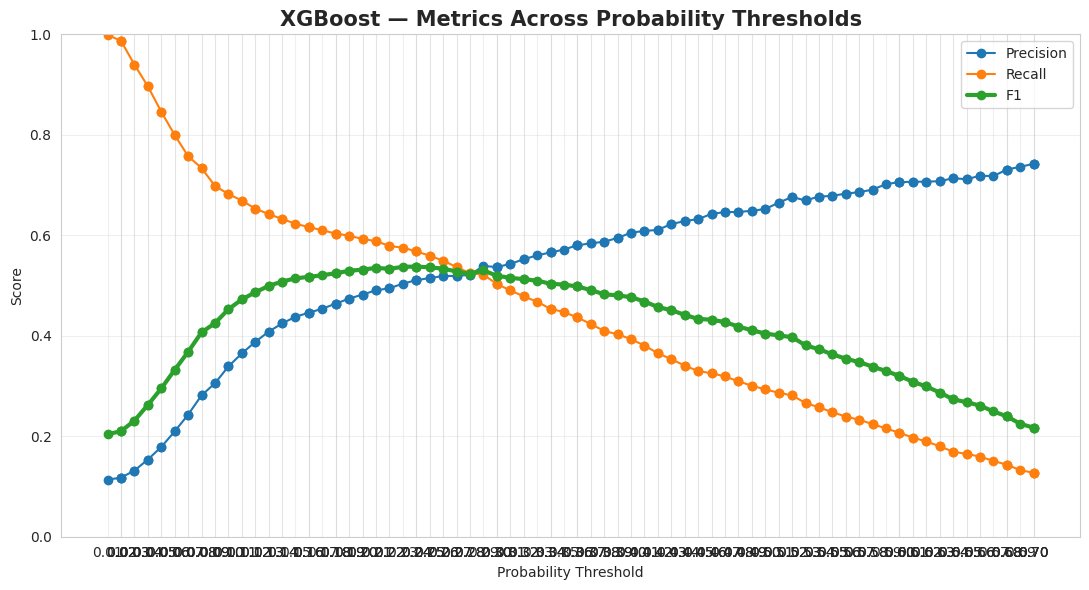

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(
    xgb_threshold_results["Threshold"],
    xgb_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    xgb_threshold_results["Threshold"],
    xgb_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    xgb_threshold_results["Threshold"],
    xgb_threshold_results["F1"],
    marker="o",
    linewidth=3,
    label="F1"
)

plt.title(
    "XGBoost — Metrics Across Probability Thresholds",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")

plt.xticks(thresholds)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### BOX 26 — CatBoost Threshold Analysis

CatBoost is the fourth model in the threshold analysis.

To keep the comparison consistent, CatBoost will use the same 25-feature engineered dataset used for the other model experiments:

- 19 original features
- 6 engineered features

The engineered features are:

- `total_contact_history`
- `contact_timing_history`
- `economic_rate_pressure`
- `employment_economic_pressure`
- `consumer_economic_index`

The additional `previously_contacted` feature is included in this 25-feature experiment.

CatBoost can handle categorical variables directly, so the categorical columns will be passed to the model without one-hot encoding.

The model parameters will remain fixed while the probability threshold is varied from 0.01 to 0.71.

The purpose is to understand the precision-recall trade-off before selecting the final threshold.

In [ ]:
# Start with the 19 original features
X_cb = X.copy()

# Add the same five engineered features
X_cb["total_contact_history"] = (
    X_cb["campaign"] + X_cb["previous"]
)

X_cb["contact_timing_history"] = (
    X_cb["pdays"] * (X_cb["previous"] + 1)
)

X_cb["economic_rate_pressure"] = (
    X_cb["emp.var.rate"] + X_cb["euribor3m"]
)

X_cb["employment_economic_pressure"] = (
    X_cb["emp.var.rate"] + X_cb["nr.employed"]
)

X_cb["consumer_economic_index"] = (
    X_cb["cons.price.idx"] + X_cb["cons.conf.idx"]
)

print("CatBoost feature count:", X_cb.shape[1])

CatBoost feature count: 25


In [ ]:
print(X_cb.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'employment_economic_pressure', 'consumer_economic_index', 'contact_timing_history', 'total_contact_history', 'economic_rate_pressure']


In [ ]:
from sklearn.model_selection import train_test_split

X_cb_train, X_cb_validation, y_cb_train, y_cb_validation = (
    train_test_split(
        X_cb,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("CatBoost training shape  :", X_cb_train.shape)
print("CatBoost validation shape:", X_cb_validation.shape)

CatBoost training shape  : (32950, 25)
CatBoost validation shape: (8238, 25)


In [ ]:
categorical_cb = X_cb_train.select_dtypes(
    include=["object"]
).columns.tolist()

cat_feature_indices = [
    X_cb_train.columns.get_loc(col)
    for col in categorical_cb
]

print("Number of categorical features:", len(categorical_cb))
print("\nCategorical features:")
print(categorical_cb)

Number of categorical features: 10

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [ ]:
from catboost import CatBoostClassifier

catboost_threshold_params = {
    "iterations": 500,
    "depth": 6,
    "learning_rate": 0.05,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": 42,
    "verbose": False,
    "thread_count": -1
}

display(
    pd.DataFrame(
        list(catboost_threshold_params.items()),
        columns=["Parameter", "Value"]
    )
)

,Parameter,Value
0,iterations,500
1,depth,6
2,learning_rate,0.05
3,loss_function,Logloss
4,eval_metric,AUC
5,random_seed,42
6,verbose,False
7,thread_count,-1


In [ ]:
catboost_threshold_model = CatBoostClassifier(
    **catboost_threshold_params
)

catboost_threshold_model.fit(
    X_cb_train,
    y_cb_train,
    cat_features=cat_feature_indices
)

print("CatBoost training completed successfully.")

CatBoost training completed successfully.


In [ ]:
catboost_validation_prob = (
    catboost_threshold_model
    .predict_proba(X_cb_validation)[:, 1]
)

print("Validation probabilities generated.")
print(
    "Number of predictions:",
    len(catboost_validation_prob)
)

Validation probabilities generated.
Number of predictions: 8238


In [ ]:
catboost_threshold_results = threshold_scan(
    model_name="CatBoost",
    y_true=y_cb_validation,
    y_probability=catboost_validation_prob,
    thresholds=thresholds
)

display(
    catboost_threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
49,CatBoost,0.25,0.886502,0.496714,0.570043,0.530858,0.814211,0.495808
48,CatBoost,0.25,0.886502,0.496714,0.570043,0.530858,0.814211,0.495808
53,CatBoost,0.27,0.888929,0.506404,0.553879,0.529079,0.814211,0.495808
52,CatBoost,0.27,0.888929,0.506404,0.553879,0.529079,0.814211,0.495808
45,CatBoost,0.24,0.884195,0.488139,0.576509,0.528656,0.814211,0.495808
47,CatBoost,0.24,0.884195,0.488139,0.576509,0.528656,0.814211,0.495808
46,CatBoost,0.24,0.884195,0.488139,0.576509,0.528656,0.814211,0.495808
44,CatBoost,0.23,0.883103,0.484305,0.581897,0.528634,0.814211,0.495808
40,CatBoost,0.21,0.879582,0.472743,0.598060,0.528069,0.814211,0.495808
41,CatBoost,0.21,0.879582,0.472743,0.598060,0.528069,0.814211,0.495808


### BOX 27 — LightGBM Threshold Analysis

LightGBM is the fifth and final model in the threshold analysis.

To keep the model comparison consistent, LightGBM will use the same engineered feature set:

- 19 original features
- 6 engineered features
- Total = 25 features

The five engineered features are:

- `total_contact_history`
- `contact_timing_history`
- `economic_rate_pressure`
- `employment_economic_pressure`
- `consumer_economic_index`

The `previously_contacted` feature is included in this 25-feature model.

As a tree-based boosting algorithm, LightGBM does not require numerical feature scaling.

The model parameters will remain fixed while the probability threshold is varied from 0.001 to 0.71.

The threshold results will be evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

In [ ]:
# Start with the 19 original features
X_lgbm = X.copy()

# Add the five engineered features

X_lgbm["total_contact_history"] = (
    X_lgbm["campaign"] + X_lgbm["previous"]
)

X_lgbm["contact_timing_history"] = (
    X_lgbm["pdays"] * (X_lgbm["previous"] + 1)
)

X_lgbm["economic_rate_pressure"] = (
    X_lgbm["emp.var.rate"] + X_lgbm["euribor3m"]
)

X_lgbm["employment_economic_pressure"] = (
    X_lgbm["emp.var.rate"] + X_lgbm["nr.employed"]
)

X_lgbm["consumer_economic_index"] = (
    X_lgbm["cons.price.idx"] + X_lgbm["cons.conf.idx"]
)

print("LightGBM feature count:", X_lgbm.shape[1])

LightGBM feature count: 25


In [ ]:
print(X_lgbm.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'employment_economic_pressure', 'consumer_economic_index', 'contact_timing_history', 'total_contact_history', 'economic_rate_pressure']


In [ ]:
from sklearn.model_selection import train_test_split

X_lgbm_train, X_lgbm_validation, y_lgbm_train, y_lgbm_validation = (
    train_test_split(
        X_lgbm,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("LightGBM training shape  :", X_lgbm_train.shape)
print("LightGBM validation shape:", X_lgbm_validation.shape)

LightGBM training shape  : (32950, 25)
LightGBM validation shape: (8238, 25)


In [ ]:
categorical_lgbm = X_lgbm_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_lgbm = X_lgbm_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:", len(categorical_lgbm))
print("Numerical features  :", len(numerical_lgbm))

Categorical features: 10
Numerical features  : 15


In [ ]:
from lightgbm import LGBMClassifier

lgbm_threshold_params = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": -1,
    "num_leaves": 31,
    "min_child_samples": 20,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "reg_alpha": 0,
    "reg_lambda": 1,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

display(
    pd.DataFrame(
        list(lgbm_threshold_params.items()),
        columns=["Parameter", "Value"]
    )
)

,Parameter,Value
0,n_estimators,500.00
1,learning_rate,0.05
2,max_depth,-1.00
3,num_leaves,31.00
4,min_child_samples,20.00
5,subsample,0.90
6,colsample_bytree,0.90
7,reg_alpha,0.00
8,reg_lambda,1.00
9,random_state,42.00


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

lgbm_threshold_encoder = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_lgbm
        ),
        (
            "num",
            "passthrough",
            numerical_lgbm
        )
    ]
)

X_lgbm_train_encoded = (
    lgbm_threshold_encoder.fit_transform(
        X_lgbm_train
    )
)

X_lgbm_validation_encoded = (
    lgbm_threshold_encoder.transform(
        X_lgbm_validation
    )
)

print(
    "Encoded training shape:",
    X_lgbm_train_encoded.shape
)

print(
    "Encoded validation shape:",
    X_lgbm_validation_encoded.shape
)

Encoded training shape: (32950, 68)
Encoded validation shape: (8238, 68)


In [ ]:
lgbm_threshold_model = LGBMClassifier(
    **lgbm_threshold_params
)

lgbm_threshold_model.fit(
    X_lgbm_train_encoded,
    y_lgbm_train
)

print("LightGBM training completed successfully.")

LightGBM training completed successfully.


In [ ]:
lgbm_validation_prob = (
    lgbm_threshold_model
    .predict_proba(
        X_lgbm_validation_encoded
    )[:, 1]
)

print("Validation probabilities generated.")
print(
    "Number of predictions:",
    len(lgbm_validation_prob)
)

Validation probabilities generated.
Number of predictions: 8238


In [ ]:
lgbm_threshold_results = threshold_scan(
    model_name="LightGBM",
    y_true=y_lgbm_validation,
    y_probability=lgbm_validation_prob,
    thresholds=thresholds
)

display(
    lgbm_threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
44,LightGBM,0.23,0.886380,0.496212,0.564655,0.528226,0.806409,0.48409
41,LightGBM,0.21,0.883224,0.484685,0.579741,0.527969,0.806409,0.48409
40,LightGBM,0.21,0.883224,0.484685,0.579741,0.527969,0.806409,0.48409
43,LightGBM,0.22,0.884924,0.490724,0.570043,0.527418,0.806409,0.48409
42,LightGBM,0.22,0.884924,0.490724,0.570043,0.527418,0.806409,0.48409
38,LightGBM,0.20,0.880675,0.475941,0.586207,0.525350,0.806409,0.48409
39,LightGBM,0.20,0.880675,0.475941,0.586207,0.525350,0.806409,0.48409
45,LightGBM,0.24,0.887109,0.499029,0.553879,0.525026,0.806409,0.48409
46,LightGBM,0.24,0.887109,0.499029,0.553879,0.525026,0.806409,0.48409
47,LightGBM,0.24,0.887109,0.499029,0.553879,0.525026,0.806409,0.48409


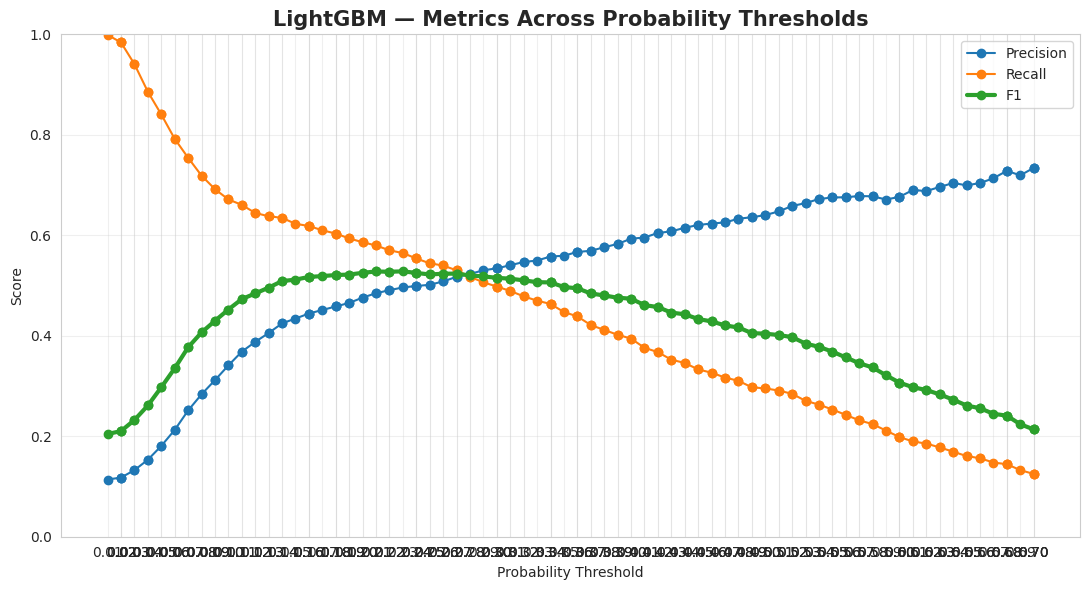

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(
    lgbm_threshold_results["Threshold"],
    lgbm_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    lgbm_threshold_results["Threshold"],
    lgbm_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    lgbm_threshold_results["Threshold"],
    lgbm_threshold_results["F1"],
    marker="o",
    linewidth=3,
    label="F1"
)

plt.title(
    "LightGBM — Metrics Across Probability Thresholds",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")

plt.xticks(thresholds)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### BOX 29 — Precision-Constrained Recall Analysis

After evaluating all five models across multiple probability thresholds, the next step is to identify configurations that provide strong recall while maintaining a minimum level of precision.

Rather than selecting a fixed number of results from each model, all model-threshold combinations will compete together.

Two precision constraints will be evaluated:

####  Strategy 1 — Precision ≥ 50%

Only configurations achieving at least 50% precision will be considered.

Among these configurations, the results will be ranked by recall, with the highest-recall configurations appearing first.

#### Strategy 2 — Precision ≥ 40%

A less restrictive precision requirement will be applied.

This allows more configurations to qualify and shows how much additional recall can be obtained when accepting a lower precision floor.

For each strategy, the top 15 model-threshold combinations will be retained.

This provides a direct comparison of the trade-off between precision and recall across all five models.

In [ ]:
all_threshold_results = pd.concat(
    [
        lr_threshold_results,
        rf_threshold_results,
        xgb_threshold_results,
        catboost_threshold_results,
        lgbm_threshold_results
    ],
    ignore_index=True
)

print(
    "Total model-threshold combinations:",
    len(all_threshold_results)
)

display(all_threshold_results)

Total model-threshold combinations: 700


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.01,0.112649,0.112649,1.000000,0.202487,0.800845,0.461585
1,Logistic Regression,0.02,0.112649,0.112649,1.000000,0.202487,0.800845,0.461585
2,Logistic Regression,0.02,0.112649,0.112649,1.000000,0.202487,0.800845,0.461585
3,Logistic Regression,0.02,0.112649,0.112649,1.000000,0.202487,0.800845,0.461585
4,Logistic Regression,0.03,0.112649,0.112649,1.000000,0.202487,0.800845,0.461585
...,...,...,...,...,...,...,...,...
695,LightGBM,0.68,0.897548,0.728261,0.144397,0.241007,0.806409,0.484090
696,LightGBM,0.69,0.896455,0.719298,0.132543,0.223840,0.806409,0.484090
697,LightGBM,0.70,0.896334,0.734177,0.125000,0.213628,0.806409,0.484090
698,LightGBM,0.70,0.896334,0.734177,0.125000,0.213628,0.806409,0.484090


In [ ]:
precision_50_results = (
    all_threshold_results[
        all_threshold_results["Precision"] >= 0.50
    ]
    .sort_values(
        by="Recall",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

precision_50_results.insert(
    0,
    "Rank",
    range(1, len(precision_50_results) + 1)
)

display(precision_50_results)

,Rank,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,XGBoost,0.23,0.888322,0.503774,0.575431,0.537223,0.810354,0.491280
1,2,XGBoost,0.24,0.890022,0.510659,0.567888,0.537755,0.810354,0.491280
2,3,XGBoost,0.24,0.890022,0.510659,0.567888,0.537755,0.810354,0.491280
3,4,XGBoost,0.24,0.890022,0.510659,0.567888,0.537755,0.810354,0.491280
4,5,Random Forest,0.61,0.888080,0.502868,0.566810,0.532928,0.816520,0.489672
5,6,Random Forest,0.61,0.888080,0.502868,0.566810,0.532928,0.816520,0.489672
6,7,XGBoost,0.25,0.890993,0.514881,0.559267,0.536157,0.810354,0.491280
7,8,XGBoost,0.25,0.890993,0.514881,0.559267,0.536157,0.810354,0.491280
8,9,Random Forest,0.62,0.888929,0.506379,0.556034,0.530046,0.816520,0.489672
9,10,Random Forest,0.62,0.888929,0.506379,0.556034,0.530046,0.816520,0.489672


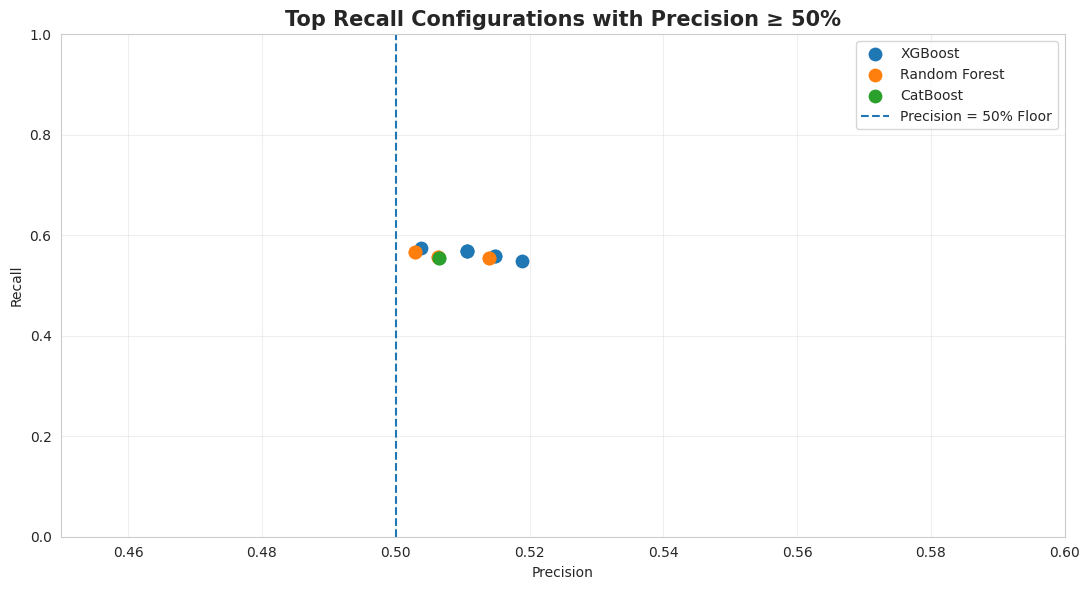

In [ ]:
plt.figure(figsize=(11, 6))

for model in precision_50_results["Model"].unique():

    model_data = precision_50_results[
        precision_50_results["Model"] == model
    ]

    plt.scatter(
        model_data["Precision"],
        model_data["Recall"],
        s=80,
        label=model
    )

plt.axvline(
    0.50,
    linestyle="--",
    label="Precision = 50% Floor"
)

plt.title(
    "Top Recall Configurations with Precision ≥ 50%",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Precision")
plt.ylabel("Recall")

plt.xlim(0.45, 0.6)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

#### Strategy 1 — Interpretation

The Precision ≥ 50% constraint represents a stricter operating condition.

Only model-threshold combinations that correctly identify at least half of their positive predictions are considered.

Within this group, configurations are ranked according to recall to identify the model and threshold capable of reaching the largest number of positive cases while maintaining the required precision floor.

In [ ]:
precision_40_results = (
    all_threshold_results[
        all_threshold_results["Precision"] >= 0.4
    ]
    .sort_values(
        by="Recall",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

precision_40_results.insert(
    0,
    "Rank",
    range(1, len(precision_40_results) + 1)
)

display(precision_40_results)

,Rank,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,CatBoost,0.12,0.852877,0.404953,0.651940,0.499587,0.814211,0.495808
1,2,CatBoost,0.12,0.852877,0.404953,0.651940,0.499587,0.814211,0.495808
2,3,CatBoost,0.13,0.859675,0.420280,0.647629,0.509754,0.814211,0.495808
3,4,CatBoost,0.13,0.859675,0.420280,0.647629,0.509754,0.814211,0.495808
4,5,Random Forest,0.45,0.854091,0.407056,0.646552,0.499584,0.816520,0.489672
5,6,Random Forest,0.45,0.854091,0.407056,0.646552,0.499584,0.816520,0.489672
6,7,XGBoost,0.13,0.854819,0.408219,0.642241,0.499162,0.810354,0.491280
7,8,XGBoost,0.13,0.854819,0.408219,0.642241,0.499162,0.810354,0.491280
8,9,CatBoost,0.14,0.864287,0.431159,0.641164,0.515598,0.814211,0.495808
9,10,CatBoost,0.14,0.864287,0.431159,0.641164,0.515598,0.814211,0.495808


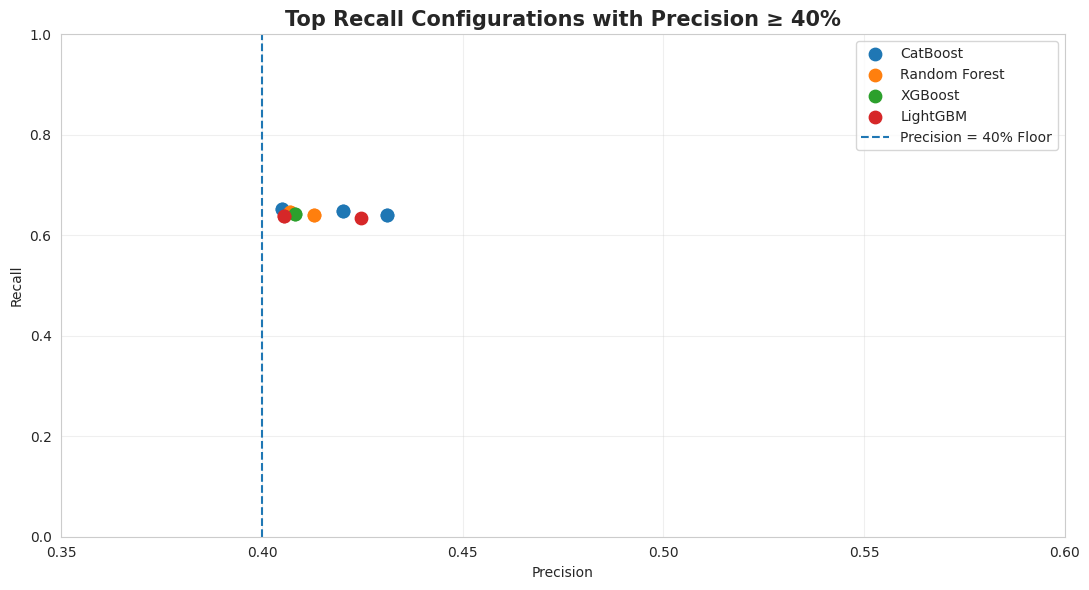

In [ ]:
plt.figure(figsize=(11, 6))

for model in precision_40_results["Model"].unique():

    model_data = precision_40_results[
        precision_40_results["Model"] == model
    ]

    plt.scatter(
        model_data["Precision"],
        model_data["Recall"],
        s=80,
        label=model
    )

plt.axvline(
    0.40,
    linestyle="--",
    label="Precision = 40% Floor"
)

plt.title(
    "Top Recall Configurations with Precision ≥ 40%",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Precision")
plt.ylabel("Recall")

plt.xlim(0.35, 0.6)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

#### Strategy 2 — Interpretation

Relaxing the precision requirement from 50% to 40% allows additional model-threshold configurations to qualify.

This provides a broader operating range and helps determine whether a meaningful increase in recall can be achieved by accepting a moderate increase in false positives.

The two strategies will be compared before selecting the final model and operating threshold.

### BOX 30 — Final Model Evaluation

The threshold analysis has now been completed for all five models.

For each model, the threshold producing the highest validation F1-score will be selected automatically from its threshold-results table.

The selected threshold will then be applied to the untouched test set.

The final evaluation will include:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Confusion Matrix

The model parameters and evaluation results will be collected directly from the trained model objects and evaluation results rather than being manually entered.

The final configurations will also be logged to MLflow for experiment tracking and reproducibility.

In [ ]:
final_models = {
    "Logistic Regression": lr_threshold_model,
    "Random Forest": rf_threshold_model,
    "XGBoost": xgb_threshold_model,
    "CatBoost": catboost_threshold_model,
    "LightGBM": lgbm_threshold_model
}

In [ ]:
threshold_tables = {
    "Logistic Regression": lr_threshold_results,
    "Random Forest": rf_threshold_results,
    "XGBoost": xgb_threshold_results,
    "CatBoost": catboost_threshold_results,
    "LightGBM": lgbm_threshold_results
}

In [ ]:
# ============================================================
# FINAL TEST SET PREPARATION
# Same untouched X_test / y_test for all models
# ============================================================

# -----------------------------
# Logistic Regression
# -----------------------------
X_lr_test = X_lr.loc[X_test.index]
y_lr_test = y_test.copy()

X_lr_test_encoded = (
    lr_threshold_preprocessor.transform(X_lr_test)
)


# -----------------------------
# Random Forest
# -----------------------------
X_rf_test = X_rf.loc[X_test.index]
y_rf_test = y_test.copy()

X_rf_test_encoded = (
    rf_threshold_encoder.transform(X_rf_test)
)


# -----------------------------
# XGBoost
# -----------------------------
X_xgb_test = X_xgb.loc[X_test.index]
y_xgb_test = y_test.copy()

X_xgb_test_encoded = (
    xgb_threshold_encoder.transform(X_xgb_test)
)


# -----------------------------
# CatBoost
# -----------------------------
X_cb_test = X_cb.loc[X_test.index]
y_cb_test = y_test.copy()


# -----------------------------
# LightGBM
# -----------------------------
X_lgbm_test = X_lgbm.loc[X_test.index]
y_lgbm_test = y_test.copy()

X_lgbm_test_encoded = (
    lgbm_threshold_encoder.transform(X_lgbm_test)
)

In [ ]:
print("Original test rows:", len(X_test))
print()

print(
    "Logistic Regression:",
    X_lr_test_encoded.shape,
    y_lr_test.shape
)

print(
    "Random Forest:",
    X_rf_test_encoded.shape,
    y_rf_test.shape
)

print(
    "XGBoost:",
    X_xgb_test_encoded.shape,
    y_xgb_test.shape
)

print(
    "CatBoost:",
    X_cb_test.shape,
    y_cb_test.shape
)

print(
    "LightGBM:",
    X_lgbm_test_encoded.shape,
    y_lgbm_test.shape
)

Original test rows: 8238

Logistic Regression: (8238, 68) (8238,)
Random Forest: (8238, 68) (8238,)
XGBoost: (8238, 68) (8238,)
CatBoost: (8238, 25) (8238,)
LightGBM: (8238, 68) (8238,)


CatBoost is showing 25 columns becouse it is trained without encoding

In [ ]:
best_thresholds = {}

for model_name, results in threshold_tables.items():

    best_row = (
        results
        .sort_values(
            by=["F1", "Recall"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    best_thresholds[model_name] = float(
        best_row["Threshold"]
    )

best_thresholds

{'Logistic Regression': 0.66,
 'Random Forest': 0.63,
 'XGBoost': 0.24,
 'CatBoost': 0.25,
 'LightGBM': 0.23}

In [ ]:
model_params = {}

for model_name, model in final_models.items():

    if hasattr(model, "get_params"):
        model_params[model_name] = model.get_params()

    else:
        model_params[model_name] = {}

In [ ]:
def evaluate_at_threshold(
    model,
    X_test,
    y_test,
    threshold
):

    probability = model.predict_proba(
        X_test
    )[:, 1]

    prediction = (
        probability >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    precision = precision_score(
        y_test,
        prediction,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        prediction,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        prediction,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        probability
    )

    pr_auc = average_precision_score(
        y_test,
        probability
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "y_pred": prediction,
        "y_probability": probability
    }

In [ ]:
# Make CatBoost test columns match the exact
# training-column order

X_cb_test = X_cb_test[
    X_cb_train.columns
]

print("CatBoost train columns :", X_cb_train.shape[1])
print("CatBoost test columns  :", X_cb_test.shape[1])

print(
    "Column order identical:",
    X_cb_test.columns.tolist() == X_cb_train.columns.tolist()
)


CatBoost train columns : 25
CatBoost test columns  : 25
Column order identical: True


In [ ]:
final_evaluation_results = []

for model_name, model in final_models.items():

    threshold = best_thresholds[model_name]

    X_test_model, y_test_model = (
        final_test_data[model_name]
    )

    metrics = evaluate_at_threshold(
        model=model,
        X_test=X_test_model,
        y_test=y_test_model,
        threshold=threshold
    )

    final_evaluation_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
        "ROC-AUC": metrics["ROC-AUC"],
        "PR-AUC": metrics["PR-AUC"]
    })

final_evaluation_df = pd.DataFrame(
    final_evaluation_results
)

display(
    final_evaluation_df.sort_values(
        "F1",
        ascending=False
    )
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
2,XGBoost,0.24,0.890022,0.510659,0.567888,0.537755,0.810354,0.491280
1,Random Forest,0.63,0.890750,0.514000,0.553879,0.533195,0.816520,0.489672
3,CatBoost,0.25,0.886502,0.496714,0.570043,0.530858,0.814211,0.495808
4,LightGBM,0.23,0.886380,0.496212,0.564655,0.528226,0.806409,0.484090
0,Logistic Regression,0.66,0.873877,0.453479,0.582974,0.510137,0.800845,0.461585


In [ ]:
import mlflow
mlflow.set_experiment(
    "Bank Marketing - Final Model Comparison"
)

<Experiment: artifact_location='/content/mlruns/2', creation_time=1787633903602, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1787633903602, lifecycle_stage='active', name='Bank Marketing - Final Model Comparison', tags={}, trace_location=None, workspace='default'>

In [ ]:
for model_name, model in final_models.items():

    threshold = best_thresholds[model_name]

    X_test_model, y_test_model = (
        final_test_data[model_name]
    )

    metrics = evaluate_at_threshold(
        model=model,
        X_test=X_test_model,
        y_test=y_test_model,
        threshold=threshold
    )

    with mlflow.start_run(
        run_name=f"{model_name} - Final"
    ):

        # Automatically capture model parameters
        params = model.get_params()

        # MLflow requires simple parameter values
        clean_params = {}

        for key, value in params.items():

            if isinstance(
                value,
                (str, int, float, bool)
            ):
                clean_params[key] = value

            elif value is None:
                clean_params[key] = "None"

            else:
                clean_params[key] = str(value)

        mlflow.log_params(clean_params)

        # Automatically log selected threshold
        mlflow.log_param(
            "selected_threshold",
            threshold
        )

        # Automatically log feature count
        mlflow.log_param(
            "feature_count",
            X_lr.shape[1]
        )

        # Automatically log evaluation metrics
        mlflow.log_metric(
            "accuracy",
            metrics["Accuracy"]
        )

        mlflow.log_metric(
            "precision",
            metrics["Precision"]
        )

        mlflow.log_metric(
            "recall",
            metrics["Recall"]
        )

        mlflow.log_metric(
            "f1",
            metrics["F1"]
        )

        mlflow.log_metric(
            "roc_auc",
            metrics["ROC-AUC"]
        )

        mlflow.log_metric(
            "pr_auc",
            metrics["PR-AUC"]
        )

        print(
            f"Logged: {model_name} | "
            f"Threshold={threshold:.4f} | "
            f"F1={metrics['F1']:.4f}"
        )

Logged: Logistic Regression | Threshold=0.6600 | F1=0.5101
Logged: Random Forest | Threshold=0.6300 | F1=0.5332
Logged: XGBoost | Threshold=0.2400 | F1=0.5378
Logged: CatBoost | Threshold=0.2500 | F1=0.5309
Logged: LightGBM | Threshold=0.2300 | F1=0.5282


### BOX 31 — Final Model Comparison & Winner Selection

After completing the threshold analysis, all five candidate models were evaluated using their selected probability thresholds on the final test set.

The objective was not simply to find the model with the highest accuracy. Since the target variable is imbalanced, accuracy alone could hide poor identification of customers who are likely to subscribe.

Instead, the final comparison focuses primarily on:

- F1-score — balance between precision and recall
- Precision — reliability of positive predictions
- Recall — ability to identify potential subscribers
- ROC-AUC — overall ranking ability
- PR-AUC — performance in the presence of class imbalance

The final test results provide the first complete view of how the five modelling approaches perform under their selected operating thresholds.

In [ ]:
final_scoreboard = (
    final_evaluation_df
    .sort_values(
        by="F1",
        ascending=False
    )
    .reset_index(drop=True)
)

final_scoreboard.insert(
    0,
    "Rank",
    range(1, len(final_scoreboard) + 1)
)

display(final_scoreboard)

,Rank,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,XGBoost,0.24,0.890022,0.510659,0.567888,0.537755,0.810354,0.491280
1,2,Random Forest,0.63,0.890750,0.514000,0.553879,0.533195,0.816520,0.489672
2,3,CatBoost,0.25,0.886502,0.496714,0.570043,0.530858,0.814211,0.495808
3,4,LightGBM,0.23,0.886380,0.496212,0.564655,0.528226,0.806409,0.484090
4,5,Logistic Regression,0.66,0.873877,0.453479,0.582974,0.510137,0.800845,0.461585


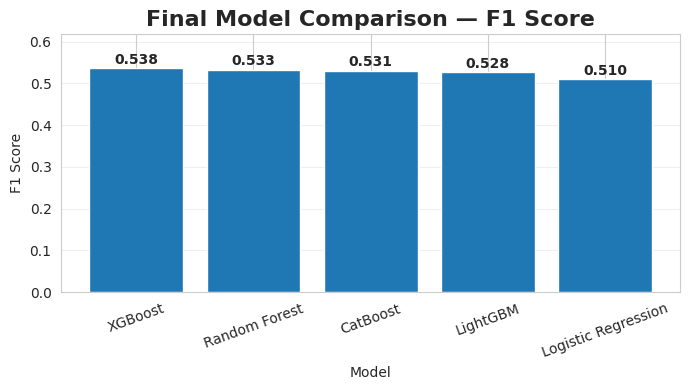

In [ ]:
plt.figure(figsize=(7, 4))

bars = plt.bar(
    final_scoreboard["Model"],
    final_scoreboard["F1"]
)

plt.title(
    "Final Model Comparison — F1 Score",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("F1 Score")

plt.ylim(
    0,
    max(final_scoreboard["F1"]) + 0.08
)

plt.xticks(rotation=20)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    final_scoreboard["F1"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{value:.3f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

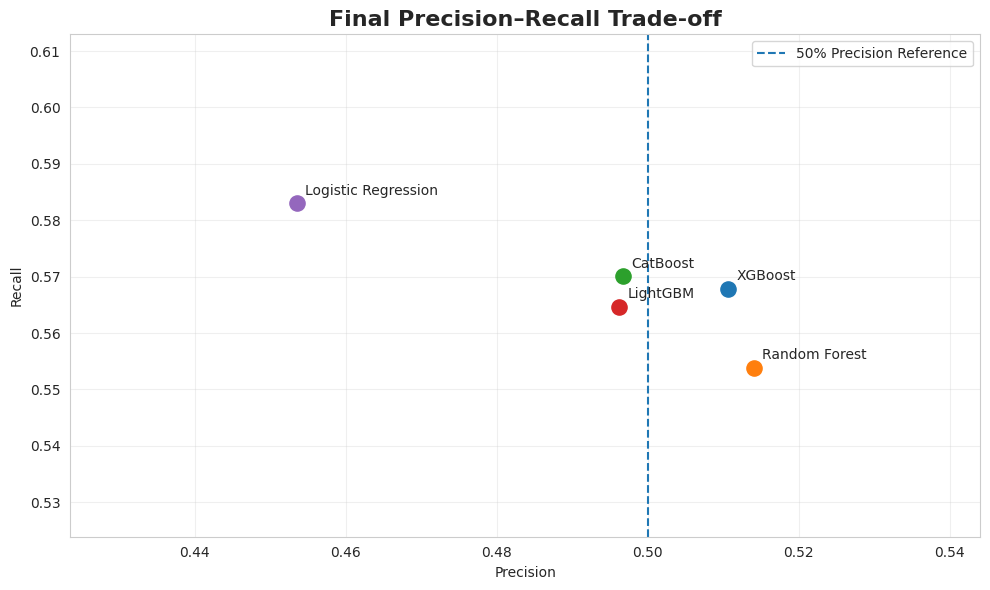

In [ ]:
plt.figure(figsize=(10, 6))

for _, row in final_scoreboard.iterrows():

    plt.scatter(
        row["Precision"],
        row["Recall"],
        s=120
    )

    plt.annotate(
        row["Model"],
        (
            row["Precision"],
            row["Recall"]
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.axvline(
    0.50,
    linestyle="--",
    label="50% Precision Reference"
)

plt.title(
    "Final Precision–Recall Trade-off",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Precision")
plt.ylabel("Recall")

plt.xlim(
    min(final_scoreboard["Precision"]) - 0.03,
    max(final_scoreboard["Precision"]) + 0.03
)

plt.ylim(
    min(final_scoreboard["Recall"]) - 0.03,
    max(final_scoreboard["Recall"]) + 0.03
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

#### What the comparison tells us

The results show that there is no single model that dominates every evaluation metric.

Logistic Regression produced the highest recall at 0.5830, meaning it was able to identify the largest proportion of actual positive cases. However, this came with lower precision and consequently a lower F1-score.

Random Forest achieved competitive performance and produced the highest ROC-AUC among the five models, but its F1-score remained slightly below XGBoost.

CatBoost achieved the highest PR-AUC, indicating strong performance when considering the imbalanced positive class. It also produced the second-highest recall after Logistic Regression.

LightGBM showed similar behaviour to the other boosting models but did not exceed their final F1-score.

XGBoost achieved the highest final F1-score of 0.5378 while maintaining a precision of 0.5107 and recall of 0.5679.

Therefore, XGBoost provides the strongest overall balance between correctly identifying positive customers and avoiding excessive false-positive predictions.

#### Champion Model — XGBoost

### Why XGBoost?

XGBoost achieved the highest F1-score among the five evaluated models:

**F1-score: 0.5378**

at a probability threshold of:

**0.24**

Final test performance:

- Accuracy: **0.8900**
- Precision: **0.5107**
- Recall: **0.5679**
- F1-score: **0.5378**
- ROC-AUC: **0.8104**
- PR-AUC: **0.4913**

The model was therefore selected as the champion model based primarily on its F1-score, while maintaining a reasonable balance between precision and recall.

The final decision was based on the complete modelling process rather than a single default threshold.

### BOX 32 — Champion XGBoost Deep Dive

After comparing all five models on the final test set, XGBoost was selected as the champion model based on its highest F1-score.

The final configuration uses:

- 25 features
- `scale_pos_weight = 1.25`
- Probability threshold = 0.24

Before considering the model final, its classification behaviour will be examined in more detail using:

1. Confusion Matrix
2. Classification Report
3. Precision–Recall behaviour
4. Feature Importance

This helps move beyond a single F1-score and understand how the model is making its predictions.

In [ ]:
# Final XGBoost threshold
XGB_FINAL_THRESHOLD = 0.24

# Probability predictions
xgb_final_proba = (
    xgb_threshold_model
    .predict_proba(X_xgb_test_encoded)[:, 1]
)

# Apply final threshold
xgb_final_pred = (
    xgb_final_proba >= XGB_FINAL_THRESHOLD
).astype(int)

print("Final threshold:", XGB_FINAL_THRESHOLD)
print("Predictions generated:", len(xgb_final_pred))

Final threshold: 0.24
Predictions generated: 8238


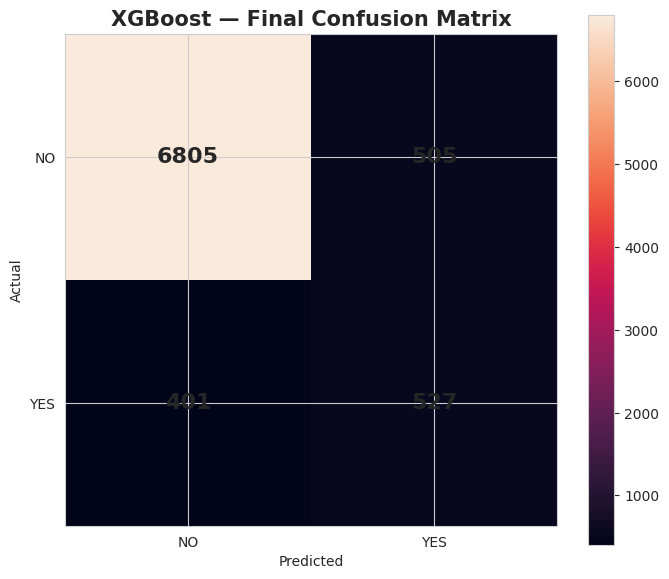

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_xgb_test,
    xgb_final_pred
)

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title(
    "XGBoost — Final Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["NO", "YES"]
)

plt.yticks(
    [0, 1],
    ["NO", "YES"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

#### Reading the Confusion Matrix

The confusion matrix gives a direct view of the model's final classification behaviour.

- **True Negative:** Correctly identified customers who did not subscribe.
- **False Positive:** Customers predicted as potential subscribers who did not subscribe.
- **False Negative:** Customers who subscribed but were missed by the model.
- **True Positive:** Customers correctly identified as potential subscribers.

For this problem, false negatives are important because they represent potential customers that the campaign failed to identify.

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_xgb_test,
        xgb_final_pred,
        target_names=["NO", "YES"],
        digits=4
    )
)

              precision    recall  f1-score   support

          NO     0.9444    0.9309    0.9376      7310
         YES     0.5107    0.5679    0.5378       928

    accuracy                         0.8900      8238
   macro avg     0.7275    0.7494    0.7377      8238
weighted avg     0.8955    0.8900    0.8925      8238



In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

xgb_final_metrics = {
    "Accuracy": accuracy_score(
        y_xgb_test,
        xgb_final_pred
    ),

    "Precision": precision_score(
        y_xgb_test,
        xgb_final_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_xgb_test,
        xgb_final_pred,
        zero_division=0
    ),

    "F1": f1_score(
        y_xgb_test,
        xgb_final_pred,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_xgb_test,
        xgb_final_proba
    ),

    "PR-AUC": average_precision_score(
        y_xgb_test,
        xgb_final_proba
    )
}

display(
    pd.DataFrame(
        [xgb_final_metrics]
    ).round(4)
)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0.89,0.5107,0.5679,0.5378,0.8104,0.4913


In [ ]:
feature_importance = xgb_threshold_model.feature_importances_

feature_names = (
    xgb_threshold_encoder
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

importance_df = (
    importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    importance_df.head(15)
)

,Feature,Importance
0,num__nr.employed,0.406425
1,num__employment_economic_pressure,0.210490
2,num__emp.var.rate,0.036553
3,cat__month_oct,0.030171
4,cat__poutcome_success,0.020360
5,num__cons.conf.idx,0.019155
6,num__contact_timing_history,0.013453
7,num__pdays,0.011014
8,cat__contact_cellular,0.009847
9,cat__month_apr,0.009762


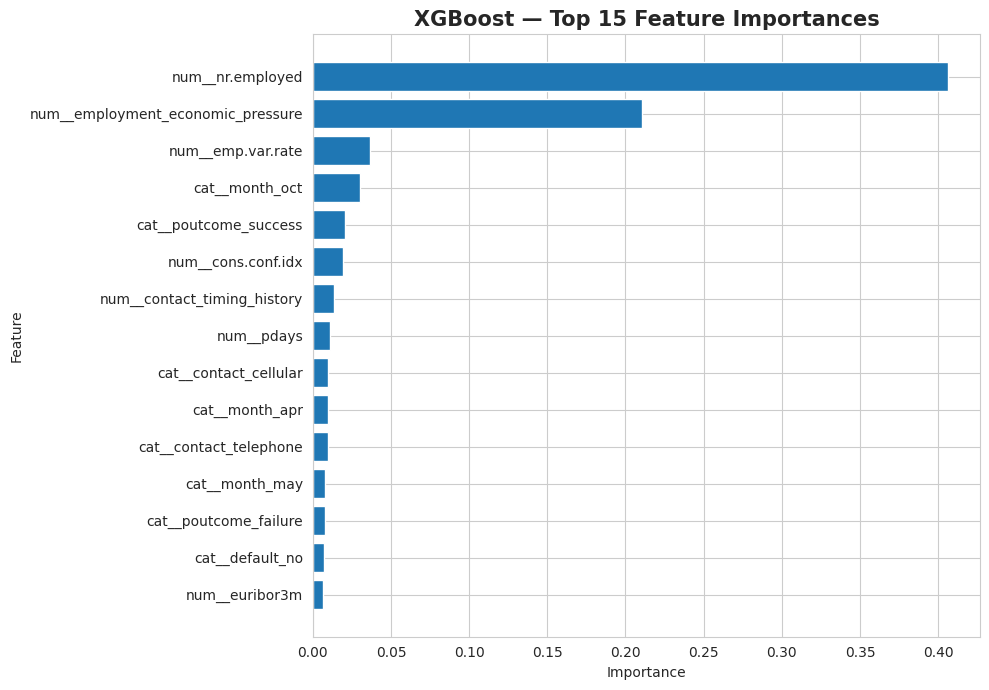

In [ ]:
top_features = (
    importance_df
    .head(15)
    .sort_values(
        "Importance"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title(
    "XGBoost — Top 15 Feature Importances",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

#### What the Champion Model Tells Us

The final XGBoost evaluation confirms that the model provides a balanced trade-off between precision and recall at the selected threshold of 0.24.

The confusion matrix shows where the model succeeds and where potential subscribers are still being missed.

The feature importance analysis provides additional insight into which customer characteristics, contact-history variables and economic indicators contributed most strongly to the model's predictions.

Importantly, the model should not be interpreted only through its overall accuracy. The positive class is the primary business interest, making precision, recall and F1-score more informative for evaluating campaign effectiveness.

The final model therefore represents a practical compromise between identifying more potential subscribers and limiting unnecessary positive predictions.

### BOX 33 — Feature Importance at Original Feature Level

The previous feature-importance analysis was based on the one-hot encoded representation used by XGBoost.

Although this is useful for the model internally, individual categorical levels such as `job_admin`, `job_technician` and `month_may` can make the interpretation difficult.

To make the results easier to understand, the importance of one-hot encoded features is aggregated back to their original feature groups.

For example:

    job_admin
    job_blue-collar
    job_services
    ...

are combined into the original:

    job

This provides a clearer view of which of the 25 original/engineered features contributed most to the final XGBoost model.

In [ ]:
# Original 25 logical features
original_features = X_xgb.columns.tolist()

encoded_feature_names = (
    xgb_threshold_encoder
    .get_feature_names_out()
)

importance_values = (
    xgb_threshold_model
    .feature_importances_
)

feature_importance_encoded = pd.DataFrame({
    "Encoded_Feature": encoded_feature_names,
    "Importance": importance_values
})

print("Encoded feature count:", len(encoded_feature_names))
print("Logical feature count:", len(original_features))


Encoded feature count: 68
Logical feature count: 25


In [ ]:
def get_original_feature(encoded_name, original_features):

    # Remove transformer prefixes
    clean_name = encoded_name.split("__", 1)[-1]

    # Find the longest matching original feature
    matches = [
        feature
        for feature in original_features
        if clean_name == feature
        or clean_name.startswith(feature + "_")
    ]

    if matches:
        return max(matches, key=len)

    return clean_name


feature_importance_encoded["Original_Feature"] = (
    feature_importance_encoded["Encoded_Feature"]
    .apply(
        lambda x: get_original_feature(
            x,
            original_features
        )
    )
)

feature_importance_original = (
    feature_importance_encoded
    .groupby(
        "Original_Feature",
        as_index=False
    )["Importance"]
    .sum()
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(feature_importance_original)

,Original_Feature,Importance
0,nr.employed,0.406425
1,employment_economic_pressure,0.210490
2,month,0.075643
3,job,0.047214
4,emp.var.rate,0.036553
5,poutcome,0.031276
6,education,0.027012
7,day_of_week,0.021327
8,contact,0.019506
9,cons.conf.idx,0.019155


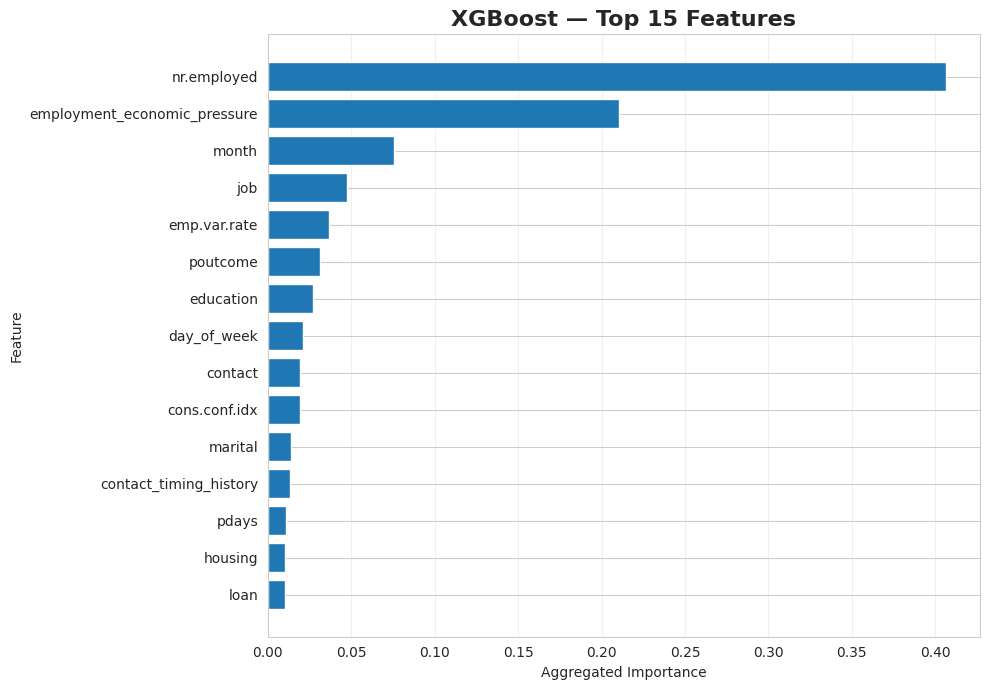

In [ ]:
top_original_features = (
    feature_importance_original
    .head(15)
    .sort_values(
        "Importance"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_original_features["Original_Feature"],
    top_original_features["Importance"]
)

plt.title(
    "XGBoost — Top 15 Features",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Aggregated Importance")
plt.ylabel("Feature")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

#### Feature Importance Interpretation

Aggregating the encoded variables back to their original feature groups makes the model easier to interpret.

Instead of treating every one-hot encoded category as an independent feature, the importance contributions of all categories belonging to the same original feature are combined.

This allows the final model to be discussed at the business-feature level.

The ranking should be interpreted as an indication of which features were most useful to the trained XGBoost model, rather than as a direct measure of causal influence.

### BOX 34 — SHAP Explainability

Feature importance tells us which features were useful to the XGBoost model, but it does not explain the direction of their influence.

SHAP (SHapley Additive exPlanations) is used to provide a more detailed interpretation of the champion model.

The analysis will answer two questions:

1. Which features have the strongest overall influence on the predictions?
2. For individual observations, which features push the prediction toward YES or NO?

SHAP is used here for model interpretation rather than for changing the model or selecting the final threshold.

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [ ]:
# Create SHAP TreeExplainer for the trained XGBoost model

xgb_shap_explainer = shap.TreeExplainer(
    xgb_threshold_model
)

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [ ]:
# Use a representative sample for SHAP analysis
SHAP_SAMPLE_SIZE = min(
    2000,
    X_xgb_test_encoded.shape[0]
)

rng = np.random.RandomState(42)

shap_indices = rng.choice(
    X_xgb_test_encoded.shape[0],
    size=SHAP_SAMPLE_SIZE,
    replace=False
)

X_shap_sample = X_xgb_test_encoded[
    shap_indices
]

print(
    "SHAP sample shape:",
    X_shap_sample.shape
)

SHAP sample shape: (2000, 68)


In [ ]:
shap_values = xgb_shap_explainer.shap_values(
    X_shap_sample
)

print(
    "SHAP values shape:",
    np.array(shap_values).shape
)

SHAP values shape: (2000, 68)


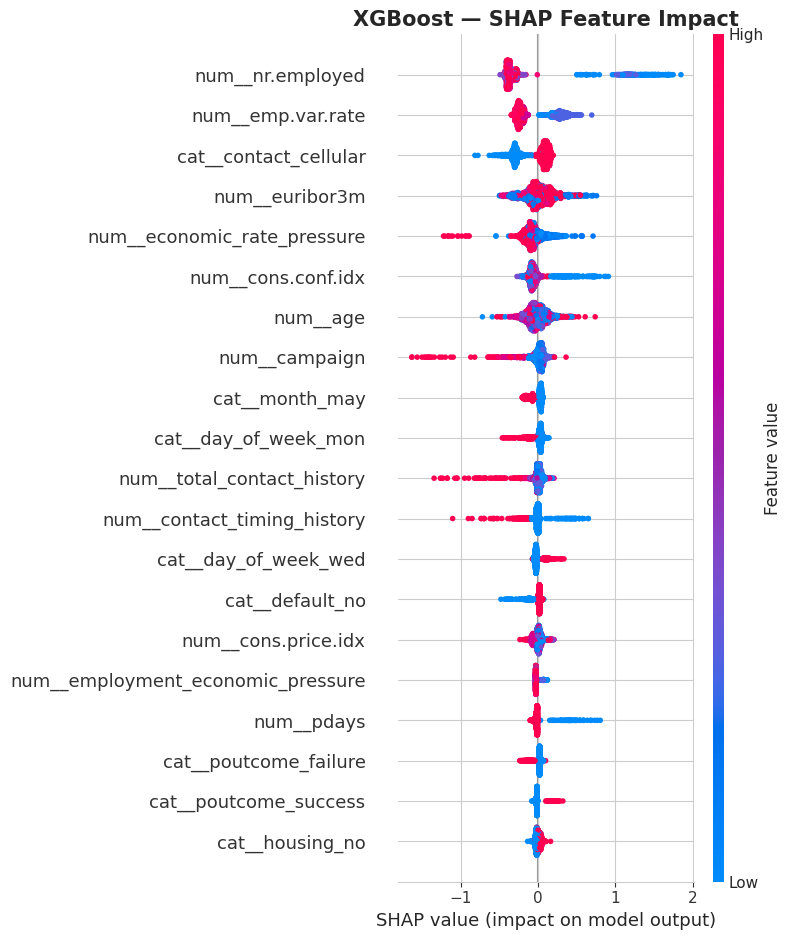

In [ ]:
shap.summary_plot(
    shap_values,
    X_shap_sample,
    feature_names=xgb_threshold_encoder.get_feature_names_out(),
    show=False
)

plt.title(
    "XGBoost — SHAP Feature Impact",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

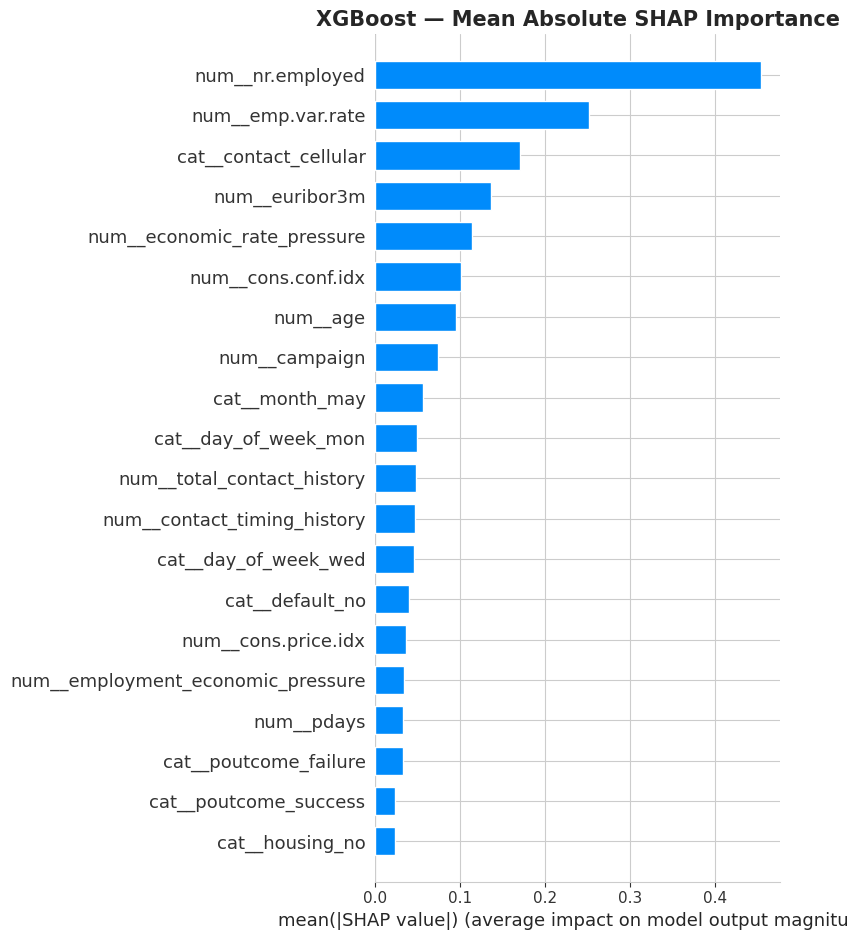

In [ ]:
shap.summary_plot(
    shap_values,
    X_shap_sample,
    feature_names=xgb_threshold_encoder.get_feature_names_out(),
    plot_type="bar",
    show=False
)

plt.title(
    "XGBoost — Mean Absolute SHAP Importance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### What SHAP Adds

The SHAP analysis provides a deeper interpretation than conventional feature importance.

While feature importance tells us which variables contributed most to the model, SHAP additionally shows the direction and magnitude of each feature's contribution to individual predictions.

A positive SHAP contribution moves the prediction toward the positive class (YES), while a negative contribution moves it toward the negative class (NO).

This allows the final XGBoost model to be interpreted at both the global and individual prediction levels.

### BOX 35 — From Model Performance to Business Decision

#### From "Best F1" to "Best Business Decision"

Throughout the modelling process, F1-score was used as the primary metric for selecting the champion model because it provides a balance between precision and recall.

However, model selection from a business perspective does not always mean maximizing F1-score.

For a bank marketing campaign, missing a customer who is genuinely interested in subscribing can represent a missed business opportunity.

Therefore, the next question becomes:

> **How much recall can we achieve while still maintaining an acceptable level of precision?**

To answer this, two practical operating scenarios are considered:

#### Strategy 1 — Precision ≥ 50%

This represents a stricter operating condition.

At least half of the customers predicted as YES must actually belong to the positive class. Among all qualifying model-threshold combinations, we look for the highest possible recall.

#### Strategy 2 — Precision ≥ 40%

This represents a more recall-oriented strategy.

By accepting a lower precision floor, the model is allowed to identify more potential customers, even though this will result in more false-positive predictions.

The goal is not to declare one strategy universally better.

Instead, these results provide the business with two different operating points depending on the cost of missing potential customers versus contacting additional customers.

In [ ]:
print(" BUSINESS STRATEGY 1 — PRECISION ≥ 50%")

display(
    precision_50_results[
        [
            "Rank",
            "Model",
            "Threshold",
            "Precision",
            "Recall",
            "F1",
            "Accuracy"
        ]
    ]
)

 BUSINESS STRATEGY 1 — PRECISION ≥ 50%


,Rank,Model,Threshold,Precision,Recall,F1,Accuracy
0,1,XGBoost,0.23,0.503774,0.575431,0.537223,0.888322
1,2,XGBoost,0.24,0.510659,0.567888,0.537755,0.890022
2,3,XGBoost,0.24,0.510659,0.567888,0.537755,0.890022
3,4,XGBoost,0.24,0.510659,0.567888,0.537755,0.890022
4,5,Random Forest,0.61,0.502868,0.566810,0.532928,0.888080
5,6,Random Forest,0.61,0.502868,0.566810,0.532928,0.888080
6,7,XGBoost,0.25,0.514881,0.559267,0.536157,0.890993
7,8,XGBoost,0.25,0.514881,0.559267,0.536157,0.890993
8,9,Random Forest,0.62,0.506379,0.556034,0.530046,0.888929
9,10,Random Forest,0.62,0.506379,0.556034,0.530046,0.888929


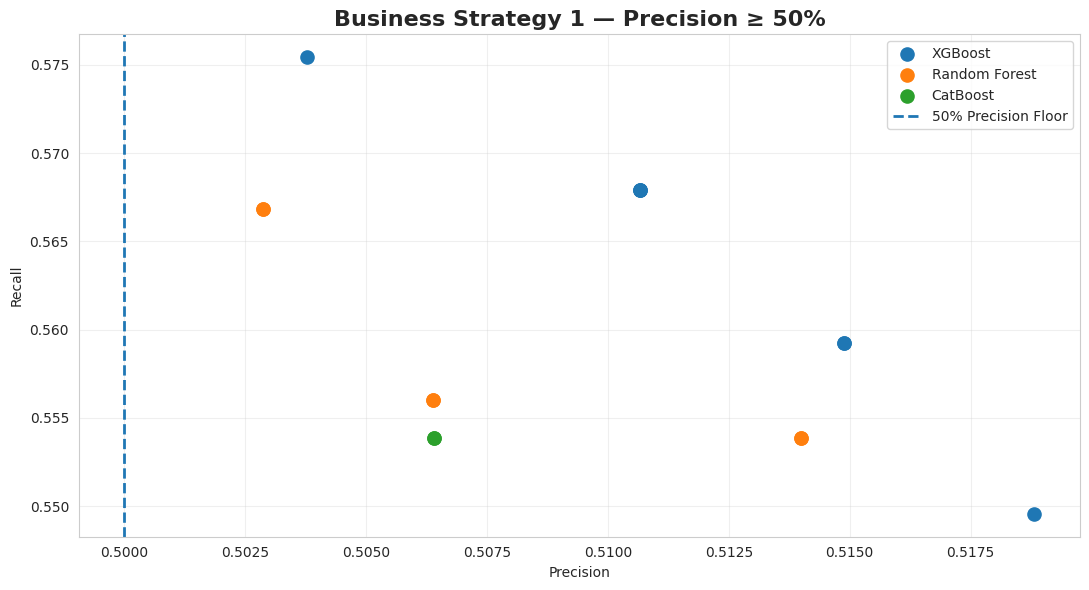

In [ ]:
plt.figure(figsize=(11, 6))

for model in precision_50_results["Model"].unique():

    model_data = precision_50_results[
        precision_50_results["Model"] == model
    ]

    plt.scatter(
        model_data["Precision"],
        model_data["Recall"],
        s=90,
        label=model
    )

plt.axvline(
    0.50,
    linestyle="--",
    linewidth=2,
    label="50% Precision Floor"
)

plt.title(
    "Business Strategy 1 — Precision ≥ 50%",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Precision")
plt.ylabel("Recall")

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
print(" BUSINESS STRATEGY 2 — PRECISION ≥ 40%")

display(
    precision_40_results[
        [
            "Rank",
            "Model",
            "Threshold",
            "Precision",
            "Recall",
            "F1",
            "Accuracy"
        ]
    ]
)

 BUSINESS STRATEGY 2 — PRECISION ≥ 40%


,Rank,Model,Threshold,Precision,Recall,F1,Accuracy
0,1,CatBoost,0.12,0.404953,0.651940,0.499587,0.852877
1,2,CatBoost,0.12,0.404953,0.651940,0.499587,0.852877
2,3,CatBoost,0.13,0.420280,0.647629,0.509754,0.859675
3,4,CatBoost,0.13,0.420280,0.647629,0.509754,0.859675
4,5,Random Forest,0.45,0.407056,0.646552,0.499584,0.854091
5,6,Random Forest,0.45,0.407056,0.646552,0.499584,0.854091
6,7,XGBoost,0.13,0.408219,0.642241,0.499162,0.854819
7,8,XGBoost,0.13,0.408219,0.642241,0.499162,0.854819
8,9,CatBoost,0.14,0.431159,0.641164,0.515598,0.864287
9,10,CatBoost,0.14,0.431159,0.641164,0.515598,0.864287


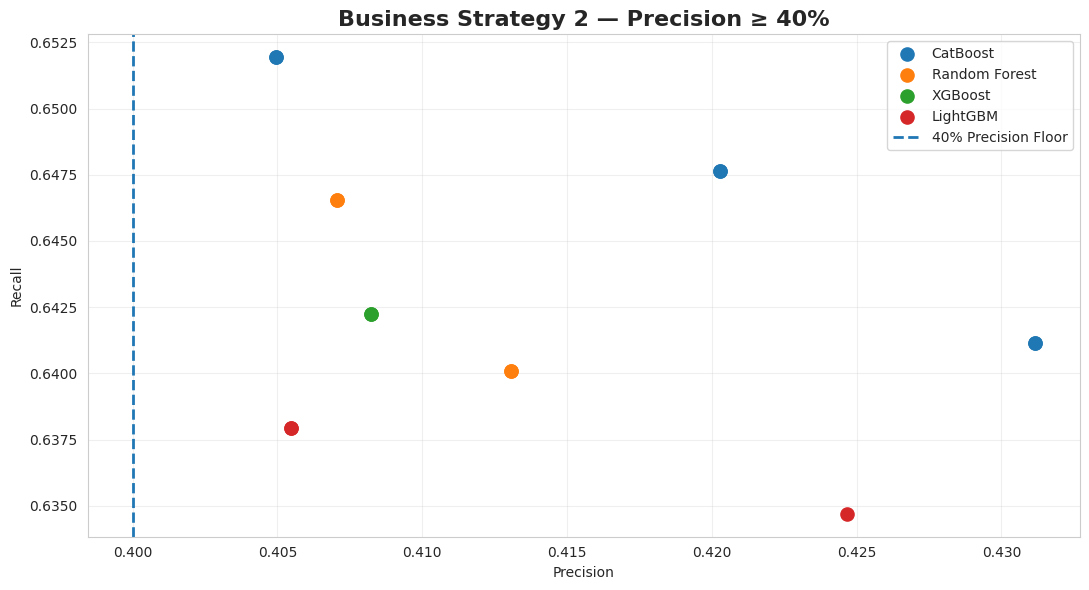

In [ ]:
plt.figure(figsize=(11, 6))

for model in precision_40_results["Model"].unique():

    model_data = precision_40_results[
        precision_40_results["Model"] == model
    ]

    plt.scatter(
        model_data["Precision"],
        model_data["Recall"],
        s=90,
        label=model
    )

plt.axvline(
    0.40,
    linestyle="--",
    linewidth=2,
    label="40% Precision Floor"
)

plt.title(
    "Business Strategy 2 — Precision ≥ 40%",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Precision")
plt.ylabel("Recall")

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

#### What Changes When We Think Like the Business?

The F1-focused analysis selected XGBoost as the overall champion because it provided the strongest balance between precision and recall.

However, the precision-constrained analysis shows that the "best" configuration depends on the business objective.

With a **50% precision floor**, the bank is asking for a more selective campaign. Every positive prediction is expected to have a relatively high probability of being a genuine positive case.

With a **40% precision floor**, the bank accepts more false positives in exchange for reaching more potential customers.

This creates two possible operating philosophies:

**Selective strategy**
→ Fewer customers contacted  
→ Higher confidence in positive predictions  
→ Lower risk of unnecessary campaign activity

**Recall-oriented strategy**
→ More potential customers identified  
→ More opportunities captured  
→ More false positives and campaign cost

Therefore, the final threshold is ultimately a business decision rather than purely a mathematical one.

#### The Precision–Recall Trade-off

An important observation from the threshold analysis is the trade-off between precision and recall.

As the classification threshold is lowered, the model becomes more willing to classify customers as potential subscribers.

This generally:

- increases Recall because fewer potential positive customers are missed
- decreases Precision because more negative customers are also classified as positive

Conversely, increasing the threshold makes the model more selective:

- Precision tends to increase
- Recall tends to decrease

Therefore, maximizing either Precision or Recall independently would not provide a balanced solution for this problem.

F1-score provides a useful compromise because it combines both Precision and Recall into a single metric.

In this project, the final operating point was selected around the region where the Precision–Recall trade-off provides a practical balance, with slightly greater emphasis on Recall because missing a potential customer represents a missed business opportunity.

The objective was therefore not to maximize Precision or Recall individually, but to identify a manageable operating point where both metrics remain useful for the campaign.

### BOX 36 — Experimental Development & Model Selection Strategy

#### From Exploration to the Final Pipeline
The final notebook represents the organized version of a much larger experimentation process.

During development, multiple experiments were conducted involving:

- Different preprocessing approaches
- Feature engineering combinations
- Different model configurations
- Class-weight adjustments
- Probability-threshold experiments
- Hyperparameter tuning approaches
- Different evaluation strategies

Not every experiment improved the model.

Some experiments produced improvements, while others reduced performance or did not provide a meaningful benefit.

Rather than keeping every experimental branch in the final notebook, the final pipeline retains the approaches that produced useful and reproducible results.

This keeps the notebook focused on the final modelling workflow while the experimentation process is used as the basis for the final feature and model choices.

#### Why was RandomizedSearchCV not used as the primary final tuning strategy?

RandomizedSearchCV was explored during the experimentation phase.

However, automated hyperparameter search did not automatically produce the best F1-score for this problem.

In particular, optimizing a model using a generic scoring objective can lead to a configuration that performs well on one metric while sacrificing Recall, which is important for this business problem.

Therefore, the final workflow focused more heavily on understanding the model behaviour through:

- Feature engineering experiments
- Class-weight experiments
- Probability-threshold analysis
- Precision–Recall trade-offs
- Validation-based comparison

The objective was not to perform the largest possible hyperparameter search, but to identify a model configuration that performs well for the actual business objective.

#### Feature Engineering Was Experiment-Driven

The engineered features were not added simply because they were mathematically possible.

They were created from domain relationships already present in the dataset and then evaluated experimentally.

The final five engineered features were retained because they provided useful signal and/or improved the modelling behaviour:

- `total_contact_history`
- `contact_timing_history`
- `economic_rate_pressure`
- `employment_economic_pressure`
- `consumer_economic_index`

Other experimental feature combinations were also explored during development but were not retained in the final pipeline when they did not provide a meaningful improvement.

Therefore, the final feature set represents the outcome of an iterative feature-engineering process rather than a single arbitrary feature-selection decision.

> **The final notebook should be viewed as the documented solution pipeline, while the experimentation phase represents the development process used to arrive at that solution.**

# Final Conclusion & Business Recommendation

### Final Conclusion

This project developed an end-to-end machine learning pipeline for predicting whether a bank customer is likely to subscribe to a term deposit.

The workflow progressed from data exploration and cleaning to feature engineering, preprocessing, comparison of five classification models, probability-threshold analysis, final evaluation and experiment tracking with MLflow.

The final model comparison showed that no single model dominated every metric.

XGBoost achieved the highest overall F1-score on the final test evaluation:

**F1 = 0.5378**

at a probability threshold of:

**0.24**

with:

- Accuracy = **0.8900**
- Precision = **0.5107**
- Recall = **0.5679**
- ROC-AUC = **0.8104**
- PR-AUC = **0.4913**

Therefore, XGBoost was selected as the champion model because it provided the strongest overall balance between Precision and Recall.

---

### But the Best Model Is Not Necessarily the Best Business Strategy

Although XGBoost was selected using F1-score, a real bank campaign would not necessarily operate at the F1-optimal threshold.

The business may care more about **how many potential customers are missed** than about maximizing a single mathematical metric.

This creates a Precision–Recall trade-off.

Lowering the threshold generally allows the model to identify more potential subscribers, increasing Recall, but it also increases false positives and reduces Precision.

Increasing the threshold makes the campaign more selective, improving Precision while potentially missing more genuine subscribers.

Therefore, the threshold should ultimately depend on the business cost of:

**False Positive → contacting a customer who is unlikely to subscribe**

versus

**False Negative → missing a customer who may actually subscribe.**

---

### Two Practical Operating Strategies

The threshold analysis therefore provides two possible business operating ranges.

### Strategy 1 — Precision ≥ 50%

A more selective campaign where at least half of the predicted positive customers are expected to belong to the positive class.

This reduces unnecessary campaign activity while still allowing the business to optimize Recall within the constraint.

### Strategy 2 — Precision ≥ 40%

A more recall-oriented campaign where the bank accepts additional false positives in exchange for identifying more potential subscribers.

This may be appropriate when the cost of missing a potential customer is significantly higher than the cost of contacting an additional customer.

The two strategies therefore represent different business operating points rather than one universally correct answer.

---

###  Final Business Recommendation

The recommended approach is to use **XGBoost as the champion model**, while treating the probability threshold as a business-controlled parameter rather than a permanently fixed value.

For a more selective campaign, the bank can operate around the **Precision ≥ 50%** region.

If the priority is to minimize missed potential customers and the campaign can tolerate more false positives, the **Precision ≥ 40%** region provides a more recall-oriented operating strategy.

The final threshold should therefore be selected after considering the actual cost of customer contact, the expected value of acquiring a new customer and the cost of missing a potential subscriber.

---

### Final Takeaway

The main outcome of this project is not simply that XGBoost achieved the highest F1-score.

The larger takeaway is that **machine-learning model selection and business decision-making are two connected but different problems**.

The model provides probabilities.

Threshold tuning converts those probabilities into decisions.

And the business determines how aggressive those decisions should be.

Therefore, the final solution provides the bank with both:

**A strong predictive model**

and

**the flexibility to choose an operating point according to business priorities.**

#  Report on Challenges Faced

1. **`pdays` had a dominant special value**

   * `999` represented customers who had not been contacted previously.
   * Because this represented the vast majority of observations, simply dropping `pdays` wasn't a good option.
   * You therefore created `previously_contacted` to preserve the information contained in the special `pdays` value while still allowing `pdays` to be used.

2. **The `pdays` transformation caused a major model-performance issue**

   * You initially converted `999 → 0`.
   * This changed the meaning of the feature because `0` can represent a very different contact-history situation.
   * Your scores dropped noticeably and the model behaviour became confusing.
   * You traced the issue back to preprocessing and corrected the representation.
   * **This is probably your strongest debugging story.**

3. **Feature engineering was not guaranteed to help**

   * You had to experiment with combinations rather than assuming engineered features would improve the model.
   * Eventually, the engineered features helped move the F1 performance from roughly **0.45 → 0.53**, around an **8-point absolute F1 improvement**.
   * That's a very good story because it demonstrates that feature engineering was actually validated experimentally.

4. **Hyperparameter search didn't automatically improve the objective**

   * RandomizedSearchCV produced disappointing results.
   * GridSearchCV also consumed significant time and did not give the improvement you expected.
   * More importantly, automated tuning could optimize the wrong thing relative to your actual business objective.
   * You therefore shifted attention toward **class weighting + threshold optimization + precision/recall trade-offs**.

5. **Threshold selection became a major challenge**

   * The default `0.5` threshold wasn't necessarily appropriate for the imbalanced target.
   * You eventually tested many thresholds and found that different models had very different useful operating points:

     * XGBoost ≈ `0.24`
     * Random Forest ≈ `0.63`
     * CatBoost ≈ `0.25`
     * LightGBM ≈ `0.23`
     * Logistic Regression ≈ `0.66`
   * This demonstrated that **one threshold cannot simply be applied to every model**.

6. **Different models were surprisingly close**

   * You might expect XGBoost to completely dominate, but the five models ended up relatively close.
   * That made model selection less trivial and forced you to look beyond accuracy.
   * For example, Logistic Regression had the **highest recall**, Random Forest the **highest ROC-AUC**, CatBoost the **highest PR-AUC**, while XGBoost had the **highest F1**.

7. **Keeping the experiment reproducible became difficult**

   * You had several experimental branches and the notebook became very long.
   * At one point you were getting a previous XGBoost F1 of `0.5386`, while the recreated experiment produced a different result.
   * Tracing that difference revealed changes in preprocessing, feature count and the treatment of `pdays`.
   * This taught you an important lesson: **small preprocessing changes can make two seemingly identical ML experiments incomparable.**

8. **Categorical preprocessing differed by model**

   * Logistic Regression, Random Forest, XGBoost and LightGBM used encoded categorical features, while CatBoost could work with categorical columns directly.
   * This caused the apparent **24/25 logical features vs 68 encoded columns** confusion.
   * You also encountered the CatBoost feature-schema/order error during final evaluation.
   * That's another legitimate implementation challenge, although I wouldn't make it one of your headline problems unless asked.

---

### And there's one **really good lesson** tying all of this together:

> **"The biggest challenge wasn't training the models. It was making sure that the data representation, evaluation metric and business objective were aligned."**

